

```

# Segmentasi Pelanggan UMKM Roti dan Kopi Bandung
## Proyek Machine Learning P4–P5 — Kasus 05

**Metode:** Unsupervised Learning — K-Means Clustering

**Sumber:** Dataset sintetis Kasus 05 dari repository resmi dosen.

### Latar Belakang
UMKM memiliki sekitar 10.000 anggota, tetapi memberikan promosi seragam kepada seluruh pelanggan. Proyek ini bertujuan mengidentifikasi segmen pelanggan berdasarkan perilaku transaksi agar strategi promosi lebih tepat sasaran.

### Tujuan
1. Memahami dan mengevaluasi kualitas data pelanggan.
2. Melakukan data cleaning dan preprocessing.
3. Membangun baseline K-Means.
4. Mengevaluasi dan menginterpretasikan hasil segmentasi.
5. Memberikan rekomendasi promosi berdasarkan profil segmen.
6. Mengintegrasikan model ke aplikasi web.

### Tahap 1 — Data Understanding
Memuat dataset asli dan memeriksa struktur awal tanpa mengubah data mentah.

```



In [1]:

# =====================================================
# 01. IMPORT LIBRARY DAN KONFIGURASI
# =====================================================

import pandas as pd
import numpy as np

RANDOM_STATE = 42

print("Pandas :", pd.__version__)
print("NumPy  :", np.__version__)
print("Random state:", RANDOM_STATE)
print("Environment siap!")


Pandas : 2.2.3
NumPy  : 2.4.6
Random state: 42
Environment siap!


In [2]:

# =====================================================
# 02. DATA LOADING
# =====================================================

DATA_URL = (
    "https://raw.githubusercontent.com/nurhikam/"
    "mkb-ml-project/main/kasus/"
    "05-segmentasi-umkm/data/raw.csv"
)

df_raw = pd.read_csv(DATA_URL)

print("Dataset berhasil dimuat!")
print("Jumlah baris :", df_raw.shape[0])
print("Jumlah kolom :", df_raw.shape[1])

display(df_raw.head())


Dataset berhasil dimuat!
Jumlah baris : 10150
Jumlah kolom : 12


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
0,PLG-08573,2025-10-10,27.0,Cidadap,shopeefood,ewallet,roti,31,1791100,7,15,4.7
1,PLG-06930,2026-05-19,33.0,Sukajadi,toko,transfer,kopi,15,Rp 365.100,10,83,4.7
2,PLG-05499,2024-02-28,31.0,Cidadap,toko,qris,roti,30,1603900,2,26,4.3
3,PLG-06747,2025-11-22,99.0,Coblong,grabfood,ewallet,kopi,12,360200,7,72,4.2
4,PLG-02367,2025-07-31,32.0,Bandung Wetan,gofood,ewallet,kopi,3,582400,13,10,4.5


In [3]:

# =====================================================
# 03. INSPEKSI STRUKTUR DATA
# =====================================================

print("=== UKURAN DATASET ===")
print(df_raw.shape)

print("\n=== NAMA KOLOM ===")
print(df_raw.columns.tolist())

print("\n=== INFORMASI DATA ===")
df_raw.info()

print("\n=== 5 DATA PERTAMA ===")
display(df_raw.head())


=== UKURAN DATASET ===
(10150, 12)

=== NAMA KOLOM ===
['id_pelanggan', 'tanggal_daftar', 'umur', 'kecamatan', 'channel_utama', 'metode_bayar', 'kategori_favorit', 'jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo', 'rating_rata']

=== INFORMASI DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10150 entries, 0 to 10149
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_pelanggan                   10150 non-null  object 
 1   tanggal_daftar                 10150 non-null  object 
 2   umur                           9942 non-null   float64
 3   kecamatan                      10150 non-null  object 
 4   channel_utama                  10150 non-null  object 
 5   metode_bayar                   10150 non-null  object 
 6   kategori_favorit               10150 non-null  object 
 7   jumlah_transaksi_6bln          10150 non-nu

,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
0,PLG-08573,2025-10-10,27.0,Cidadap,shopeefood,ewallet,roti,31,1791100,7,15,4.7
1,PLG-06930,2026-05-19,33.0,Sukajadi,toko,transfer,kopi,15,Rp 365.100,10,83,4.7
2,PLG-05499,2024-02-28,31.0,Cidadap,toko,qris,roti,30,1603900,2,26,4.3
3,PLG-06747,2025-11-22,99.0,Coblong,grabfood,ewallet,kopi,12,360200,7,72,4.2
4,PLG-02367,2025-07-31,32.0,Bandung Wetan,gofood,ewallet,kopi,3,582400,13,10,4.5



## 2. Data Quality Audit

Tahap ini bertujuan mengidentifikasi permasalahan kualitas data sebelum dilakukan pembersihan.

Pemeriksaan mencakup:
- Missing values
- Duplikasi baris dan ID pelanggan
- Konsistensi format data
- Validitas nilai dan kategori

Seluruh pemeriksaan dilakukan pada `df_raw` tanpa mengubah dataset asli.


In [4]:

# =====================================================
# 04. DATA QUALITY AUDIT - MISSING & DUPLICATES
# =====================================================

# A. Pemeriksaan missing values
missing_summary = pd.DataFrame({
    "jumlah_missing": df_raw.isna().sum(),
    "persentase_missing": (
        df_raw.isna().mean() * 100
    ).round(2)
})

print("=== MISSING VALUES ===")
display(missing_summary)

# B. Pemeriksaan duplikasi
print("\n=== PEMERIKSAAN DUPLIKASI ===")

print("Jumlah baris:", len(df_raw))

print(
    "Jumlah ID unik:",
    df_raw["id_pelanggan"].nunique()
)

print(
    "Duplikat seluruh baris:",
    df_raw.duplicated().sum()
)

print(
    "Duplikat ID pelanggan:",
    df_raw.duplicated(
        subset=["id_pelanggan"]
    ).sum()
)


=== MISSING VALUES ===


,jumlah_missing,persentase_missing
id_pelanggan,0,0.00
tanggal_daftar,0,0.00
umur,208,2.05
kecamatan,0,0.00
channel_utama,0,0.00
metode_bayar,0,0.00
kategori_favorit,0,0.00
jumlah_transaksi_6bln,0,0.00
total_belanja_rp,0,0.00
hari_sejak_transaksi_terakhir,0,0.00



=== PEMERIKSAAN DUPLIKASI ===
Jumlah baris: 10150
Jumlah ID unik: 10000
Duplikat seluruh baris: 90
Duplikat ID pelanggan: 150


In [5]:

# =====================================================
# 05. DATA QUALITY AUDIT - FORMAT & CATEGORY
# =====================================================

# A. Pemeriksaan format total belanja
print("=== FORMAT TOTAL BELANJA ===")

print("Tipe data:", df_raw["total_belanja_rp"].dtype)

format_belanja = (
    df_raw["total_belanja_rp"]
    .astype("string")
    .str.strip()
)

bukan_angka_biasa = ~format_belanja.str.fullmatch(
    r"[0-9]+",
    na=False
)

print(
    "Jumlah nilai bukan format digit biasa:",
    bukan_angka_biasa.sum()
)

print("\nContoh format yang perlu diperiksa:")
display(
    df_raw.loc[
        bukan_angka_biasa,
        ["id_pelanggan", "total_belanja_rp"]
    ].head(10)
)

# B. Pemeriksaan kategori
kolom_kategori = [
    "kecamatan",
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

for kolom in kolom_kategori:
    print(f"\n=== {kolom.upper()} ===")
    print("Jumlah kategori unik:", df_raw[kolom].nunique())
    print(df_raw[kolom].value_counts(dropna=False))


=== FORMAT TOTAL BELANJA ===
Tipe data: object
Jumlah nilai bukan format digit biasa: 507

Contoh format yang perlu diperiksa:


,id_pelanggan,total_belanja_rp
1,PLG-06930,Rp 365.100
29,PLG-06885,Rp 446.400
39,PLG-05123,Rp 1.044.300
50,PLG-09252,Rp 59.700
54,PLG-01775,Rp 103.400
77,PLG-02348,Rp 94.500
102,PLG-04970,Rp 149.600
121,PLG-04854,Rp 264.100
150,PLG-02273,Rp 1.558.700
176,PLG-05949,Rp 2.198.900



=== KECAMATAN ===
Jumlah kategori unik: 15
kecamatan
Buahbatu             1046
Cidadap              1029
Sumur Bandung        1002
Arcamanik            1000
Sukajadi              989
Bandung Wetan         984
Lengkong              976
Antapani              976
Coblong               951
Cibeunying Kidul      943
SUKAJADI               68
Bdg Wetan              57
Buah Batu              47
coblong                46
Cibeunying Kidul       36
Name: count, dtype: int64

=== CHANNEL_UTAMA ===
Jumlah kategori unik: 4
channel_utama
toko          4666
gofood        2174
shopeefood    1705
grabfood      1605
Name: count, dtype: int64

=== METODE_BAYAR ===
Jumlah kategori unik: 4
metode_bayar
qris        4567
tunai       2546
ewallet     1975
transfer    1062
Name: count, dtype: int64

=== KATEGORI_FAVORIT ===
Jumlah kategori unik: 4
kategori_favorit
kopi               4175
roti               3488
kue_ulang_tahun    1257
paket_snack        1230
Name: count, dtype: int64


In [6]:

# =====================================================
# 06. INVESTIGASI DUPLIKAT PELANGGAN
# =====================================================

# Salinan sementara untuk analisis
df_tanpa_duplikat_identik = df_raw.drop_duplicates()

# Cari ID yang masih muncul lebih dari sekali
duplikat_konflik = df_tanpa_duplikat_identik[
    df_tanpa_duplikat_identik.duplicated(
        subset=["id_pelanggan"], keep=False
    )
].sort_values("id_pelanggan")

print("=== INVESTIGASI DUPLIKAT ===")

print(
    "Duplikat identik yang teridentifikasi:",
    len(df_raw) - len(df_tanpa_duplikat_identik)
)

print(
    "Jumlah ID dengan catatan tidak identik:",
    duplikat_konflik["id_pelanggan"].nunique()
)

print("\nContoh data dengan ID sama tetapi isi berbeda:")
display(duplikat_konflik.head(12))

print("\n=== VARIASI PENULISAN KECAMATAN ===")
for nilai in sorted(df_raw["kecamatan"].unique()):
    print(repr(nilai))


=== INVESTIGASI DUPLIKAT ===
Duplikat identik yang teridentifikasi: 90
Jumlah ID dengan catatan tidak identik: 60

Contoh data dengan ID sama tetapi isi berbeda:


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
1255,PLG-00079,2025-12-21,45.0,Sukajadi,toko,transfer,roti,21,1003600,11,16,4.2
8828,PLG-00079,2025-12-21,45.0,Sukajadi,toko,transfer,roti,21,1003600,10,16,4.2
7697,PLG-00276,2024-03-09,25.0,Arcamanik,gofood,transfer,paket_snack,9,398800,12,83,3.5
1902,PLG-00276,2024-03-09,25.0,Arcamanik,gofood,transfer,paket_snack,9,398800,13,83,3.5
4168,PLG-00335,2025-09-30,24.0,Bandung Wetan,gofood,tunai,paket_snack,13,422200,10,90,4.6
225,PLG-00335,2025-09-30,24.0,Bandung Wetan,gofood,tunai,paket_snack,13,422200,11,90,4.6
5820,PLG-00429,2024-11-19,26.0,Cibeunying Kidul,toko,qris,paket_snack,16,570200,18,77,4.4
10007,PLG-00429,2024-11-19,26.0,Cibeunying Kidul,toko,qris,paket_snack,16,570200,17,77,4.4
2262,PLG-00607,2024-10-17,19.0,Sukajadi,grabfood,qris,kopi,3,139100,114,22,3.9
10047,PLG-00607,2024-10-17,19.0,Sukajadi,grabfood,qris,kopi,3,139100,113,22,3.9



=== VARIASI PENULISAN KECAMATAN ===
'Antapani'
'Arcamanik'
'Bandung Wetan'
'Bdg Wetan'
'Buah Batu'
'Buahbatu'
'Cibeunying Kidul'
'Cibeunying Kidul '
'Cidadap'
'Coblong'
'Lengkong'
'SUKAJADI'
'Sukajadi'
'Sumur Bandung'
'coblong'


In [7]:

# =====================================================
# 07. VALIDASI NILAI NUMERIK DAN TANGGAL
# =====================================================

# Konversi sementara tanpa mengubah df_raw
belanja_teks = (
    df_raw["total_belanja_rp"]
    .astype("string")
    .str.strip()
)

# Format yang diterima: angka biasa atau Rp dengan
# pemisah ribuan titik
format_valid = belanja_teks.str.fullmatch(
    r"(?:[0-9]+|Rp\s*[0-9]{1,3}(?:\.[0-9]{3})+)",
    na=False
)

belanja_angka = pd.to_numeric(
    belanja_teks
    .str.replace(r"^Rp\s*", "", regex=True)
    .str.replace(".", "", regex=False),
    errors="coerce"
)

tanggal = pd.to_datetime(
    df_raw["tanggal_daftar"],
    errors="coerce"
)

audit = {
    "Umur < 17 atau > 90": (
        (df_raw["umur"] < 17) |
        (df_raw["umur"] > 90)
    ).sum(),

    "Transaksi negatif": (
        df_raw["jumlah_transaksi_6bln"] < 0
    ).sum(),

    "Belanja negatif": (belanja_angka < 0).sum(),

    "Format belanja tidak dikenali": (
        ~format_valid
    ).sum(),

    "Belanja gagal dikonversi": (
        belanja_angka.isna()
    ).sum(),

    "Recency negatif": (
        df_raw["hari_sejak_transaksi_terakhir"] < 0
    ).sum(),

    "Promo di luar 0-100%": (
        (df_raw["persen_pakai_promo"] < 0) |
        (df_raw["persen_pakai_promo"] > 100)
    ).sum(),

    "Rating di luar 1-5": (
        (df_raw["rating_rata"] < 1) |
        (df_raw["rating_rata"] > 5)
    ).sum(),

    "Tanggal tidak valid": tanggal.isna().sum(),

    "Tanggal daftar setelah Juni 2026": (
        tanggal > pd.Timestamp("2026-06-30")
    ).sum()
}

print("=== AUDIT VALIDITAS DATA ===")
display(pd.DataFrame(
    audit.items(),
    columns=["Pemeriksaan", "Jumlah"]
))

print("\n=== DISTRIBUSI ANGKA ===")
kolom_numerik = [
    "jumlah_transaksi_6bln",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata"
]

display(df_raw[kolom_numerik].describe())

print("\n=== DISTRIBUSI TOTAL BELANJA ===")
display(belanja_angka.describe())


=== AUDIT VALIDITAS DATA ===


,Pemeriksaan,Jumlah
0,Umur < 17 atau > 90,658
1,Transaksi negatif,0
2,Belanja negatif,0
3,Format belanja tidak dikenali,0
4,Belanja gagal dikonversi,0
5,Recency negatif,0
6,Promo di luar 0-100%,0
7,Rating di luar 1-5,0
8,Tanggal tidak valid,0
9,Tanggal daftar setelah Juni 2026,0



=== DISTRIBUSI ANGKA ===


,jumlah_transaksi_6bln,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
count,10150.000000,10150.000000,10150.00000,9338.000000
mean,12.515862,41.859113,38.49468,4.151928
std,11.627520,49.454730,28.02179,0.524955
min,1.000000,0.000000,0.00000,2.000000
25%,3.000000,6.000000,16.00000,3.800000
50%,8.000000,16.000000,28.00000,4.200000
75%,20.000000,75.000000,65.75000,4.500000
max,56.000000,225.000000,100.00000,5.000000



=== DISTRIBUSI TOTAL BELANJA ===


,total_belanja_rp
count,10150.0
mean,692690.384236
std,647889.223572
min,11900.0
25%,151625.0
50%,424450.0
75%,1144175.0
max,3424200.0


In [8]:

# =====================================================
# 08. INVESTIGASI NILAI DAN KONFLIK DATA
# =====================================================

# A. Distribusi umur di luar rentang pemeriksaan
umur_tidak_wajar = df_raw.loc[
    (df_raw["umur"] < 17) | (df_raw["umur"] > 90),
    "umur"
]

print("=== NILAI UMUR DI LUAR 17-90 ===")
print(
    umur_tidak_wajar.value_counts()
    .sort_index()
    .to_string()
)

print("\n=== PEMERIKSAAN RECENCY ===")

recency = df_raw["hari_sejak_transaksi_terakhir"]

print("Recency > 183 hari:", (recency > 183).sum())

print("\nContoh pelanggan dengan recency > 183:")
display(
    df_raw.loc[
        recency > 183,
        [
            "id_pelanggan",
            "jumlah_transaksi_6bln",
            "hari_sejak_transaksi_terakhir"
        ]
    ].head(10)
)

# B. Kolom apa saja yang berbeda pada ID ganda?
print("\n=== PERBEDAAN PADA ID GANDA ===")

variasi = (
    duplikat_konflik
    .groupby("id_pelanggan")
    .nunique(dropna=False)
)

jumlah_konflik = (
    (variasi > 1)
    .sum()
    .sort_values(ascending=False)
)

display(
    jumlah_konflik[jumlah_konflik > 0]
    .rename("jumlah_ID_berbeda")
    .to_frame()
)

# C. Selisih recency untuk pasangan konflik
selisih_recency = (
    duplikat_konflik
    .groupby("id_pelanggan")[
        "hari_sejak_transaksi_terakhir"
    ]
    .agg(lambda x: x.max() - x.min())
)

print("\n=== SELISIH RECENCY PADA ID GANDA ===")
print(selisih_recency.value_counts().sort_index())


=== NILAI UMUR DI LUAR 17-90 ===
umur
0.0       27
1.0       20
16.0     558
99.0      25
120.0     28

=== PEMERIKSAAN RECENCY ===
Recency > 183 hari: 50

Contoh pelanggan dengan recency > 183:


,id_pelanggan,jumlah_transaksi_6bln,hari_sejak_transaksi_terakhir
129,PLG-06375,3,185
482,PLG-06520,1,191
629,PLG-01801,2,197
883,PLG-08467,3,205
1015,PLG-07889,1,215
1225,PLG-01152,1,195
1305,PLG-01889,5,202
1458,PLG-05048,3,197
1520,PLG-05093,3,200
1824,PLG-07099,3,192



=== PERBEDAAN PADA ID GANDA ===


,jumlah_ID_berbeda
hari_sejak_transaksi_terakhir,60



=== SELISIH RECENCY PADA ID GANDA ===
hari_sejak_transaksi_terakhir
1    60
Name: count, dtype: int64


In [9]:

# =====================================================
# 09. FINAL DATA QUALITY INVESTIGATION
# =====================================================

import pandas as pd

TANGGAL_ACUAN = pd.Timestamp("2026-06-30")
AWAL_PERIODE = pd.Timestamp("2026-01-01")

# A. Investigasi nilai umur
print("=== DISTRIBUSI UMUR DI LUAR 17-90 ===")

mask_umur = (
    (df_raw["umur"] < 17) |
    (df_raw["umur"] > 90)
)

display(
    df_raw.loc[mask_umur, "umur"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("umur")
    .reset_index(name="jumlah")
)

# B. Konsistensi periode transaksi
print("\n=== KONSISTENSI PERIODE TRANSAKSI ===")

maks_recency_periode = (
    TANGGAL_ACUAN - AWAL_PERIODE
).days

mask_recency = (
    df_raw["hari_sejak_transaksi_terakhir"]
    > maks_recency_periode
)

print("Maksimum recency sesuai periode:", maks_recency_periode)
print("Jumlah melebihi periode:", mask_recency.sum())

print("\nDistribusi recency yang melebihi periode:")
display(
    df_raw.loc[
        mask_recency,
        "hari_sejak_transaksi_terakhir"
    ].describe()
)

# C. Konsistensi tanggal keanggotaan
print("\n=== KONSISTENSI TANGGAL PENDAFTARAN ===")

tanggal_daftar = pd.to_datetime(
    df_raw["tanggal_daftar"],
    errors="coerce"
)

tanggal_transaksi_terakhir = (
    TANGGAL_ACUAN -
    pd.to_timedelta(
        df_raw["hari_sejak_transaksi_terakhir"],
        unit="D"
    )
)

mask_transaksi_sebelum_daftar = (
    tanggal_transaksi_terakhir < tanggal_daftar
)

print(
    "Transaksi terakhir sebelum tanggal daftar:",
    mask_transaksi_sebelum_daftar.sum()
)

print(
    "Tanggal daftar setelah tanggal acuan:",
    (tanggal_daftar > TANGGAL_ACUAN).sum()
)

# D. Konsistensi transaksi dan nominal belanja
print("\n=== KONSISTENSI TRANSAKSI DAN BELANJA ===")

print(
    "Transaksi nol atau negatif:",
    (df_raw["jumlah_transaksi_6bln"] <= 0).sum()
)

print(
    "Transaksi positif tetapi belanja nol:",
    (
        (df_raw["jumlah_transaksi_6bln"] > 0) &
        (belanja_angka == 0)
    ).sum()
)

# E. Ringkasan data audit
print("\n=== RINGKASAN ===")
print("Data mentah:", len(df_raw))
print("ID pelanggan unik:", df_raw["id_pelanggan"].nunique())
print("Duplikat identik:", df_raw.duplicated().sum())
print("Recency melebihi periode:", mask_recency.sum())

print("\nFinal investigation selesai.")


=== DISTRIBUSI UMUR DI LUAR 17-90 ===


,umur,jumlah
0,0.0,27
1,1.0,20
2,16.0,558
3,99.0,25
4,120.0,28



=== KONSISTENSI PERIODE TRANSAKSI ===
Maksimum recency sesuai periode: 180
Jumlah melebihi periode: 67

Distribusi recency yang melebihi periode:


,hari_sejak_transaksi_terakhir
count,67.000000
mean,192.925373
std,12.200737
min,181.000000
25%,183.500000
50%,191.000000
75%,197.000000
max,225.000000



=== KONSISTENSI TANGGAL PENDAFTARAN ===
Transaksi terakhir sebelum tanggal daftar: 289
Tanggal daftar setelah tanggal acuan: 0

=== KONSISTENSI TRANSAKSI DAN BELANJA ===
Transaksi nol atau negatif: 0
Transaksi positif tetapi belanja nol: 0

=== RINGKASAN ===
Data mentah: 10150
ID pelanggan unik: 10000
Duplikat identik: 90
Recency melebihi periode: 67

Final investigation selesai.



## 3. Data Cleaning

Pembersihan data dilakukan berdasarkan hasil data quality audit.

Tahapan:
1. Menghapus duplikat identik.
2. Merekonsiliasi ID pelanggan ganda.
3. Mengonversi total belanja menjadi numerik.
4. Mengonversi tanggal pendaftaran.
5. Menstandarisasi nama kecamatan.
6. Menangani umur yang tidak valid.
7. Menandai anomali waktu tanpa langsung menghapus pelanggan.

Data asli (`df_raw`) tetap dipertahankan untuk menjaga keterlacakan proses.

**Asumsi:** Jika ID yang sama memiliki dua catatan yang hanya berbeda satu hari pada recency, dipilih recency terkecil sebagai pendekatan konservatif untuk aktivitas terkini. Tidak tersedia timestamp untuk memastikan catatan mana yang paling mutakhir.


In [10]:

# =====================================================
# 10. DATA CLEANING
# =====================================================

# A. Membuat salinan data
df_clean = df_raw.copy(deep=True)

# B. Menghapus duplikat identik
df_clean = df_clean.drop_duplicates()

# C. Rekonsiliasi ID pelanggan ganda
# Pilih recency terkecil untuk pasangan konflik
df_clean = (
    df_clean
    .sort_values(
        ["id_pelanggan", "hari_sejak_transaksi_terakhir"],
        ascending=[True, True],
        kind="mergesort"
    )
    .drop_duplicates(subset="id_pelanggan", keep="first")
    .reset_index(drop=True)
)

# D. Konversi total belanja
belanja_bersih = (
    df_clean["total_belanja_rp"]
    .astype("string")
    .str.strip()
    .str.replace(r"^Rp\s*", "", regex=True)
    .str.replace(".", "", regex=False)
)

df_clean["total_belanja_rp"] = pd.to_numeric(
    belanja_bersih,
    errors="raise"
)

# E. Konversi tanggal
df_clean["tanggal_daftar"] = pd.to_datetime(
    df_clean["tanggal_daftar"],
    format="%Y-%m-%d",
    errors="raise"
)

# F. Standardisasi kecamatan
mapping_kecamatan = {
    "antapani": "Antapani",
    "arcamanik": "Arcamanik",
    "bandung wetan": "Bandung Wetan",
    "bdg wetan": "Bandung Wetan",
    "buah batu": "Buahbatu",
    "buahbatu": "Buahbatu",
    "cibeunying kidul": "Cibeunying Kidul",
    "cidadap": "Cidadap",
    "coblong": "Coblong",
    "lengkong": "Lengkong",
    "sukajadi": "Sukajadi",
    "sumur bandung": "Sumur Bandung"
}

kecamatan_normal = (
    df_clean["kecamatan"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

df_clean["kecamatan"] = kecamatan_normal.map(
    mapping_kecamatan
)

# G. Menandai umur mencurigakan
df_clean["flag_umur_perlu_verifikasi"] = (
    df_clean["umur"].isin([0, 1, 99, 120])
)

# Umur 0, 1, 120 diperlakukan sebagai tidak valid
# Umur 99 tetap dipertahankan, tetapi diberi flag
df_clean.loc[
    df_clean["umur"].isin([0, 1, 120]),
    "umur"
] = np.nan

# H. Flag anomali periode transaksi
TANGGAL_ACUAN = pd.Timestamp("2026-06-30")
AWAL_PERIODE = pd.Timestamp("2026-01-01")

BATAS_RECENCY = (
    TANGGAL_ACUAN - AWAL_PERIODE
).days

df_clean["flag_recency_luar_periode"] = (
    df_clean["hari_sejak_transaksi_terakhir"]
    > BATAS_RECENCY
)

# I. Flag urutan waktu
tanggal_transaksi_terakhir = (
    TANGGAL_ACUAN -
    pd.to_timedelta(
        df_clean["hari_sejak_transaksi_terakhir"],
        unit="D"
    )
)

df_clean["flag_transaksi_sebelum_daftar"] = (
    tanggal_transaksi_terakhir
    < df_clean["tanggal_daftar"]
)

print("Proses data cleaning berhasil dijalankan.")


Proses data cleaning berhasil dijalankan.


In [11]:

# =====================================================
# 11. DATA CLEANING VALIDATION
# =====================================================

print("=== JUMLAH DATA ===")
print("Sebelum cleaning:", len(df_raw))
print("Sesudah cleaning:", len(df_clean))

print("\n=== DUPLIKASI ===")
print("Duplikat baris:", df_clean.duplicated().sum())
print(
    "Duplikat ID:",
    df_clean["id_pelanggan"].duplicated().sum()
)

print("\n=== TIPE DATA ===")
print(df_clean.dtypes)

print("\n=== KECAMATAN SETELAH STANDARDISASI ===")
print("Jumlah kategori:", df_clean["kecamatan"].nunique())
print(df_clean["kecamatan"].value_counts())

print("\n=== ANOMALI YANG DIPERTAHANKAN ===")
kolom_flag = [
    "flag_umur_perlu_verifikasi",
    "flag_recency_luar_periode",
    "flag_transaksi_sebelum_daftar"
]

display(df_clean[kolom_flag].sum().to_frame("jumlah"))

print("\n=== MISSING VALUES SETELAH CLEANING ===")
display(
    df_clean.isna().sum().to_frame("jumlah_missing")
)

# Pemeriksaan otomatis
assert len(df_clean) == df_raw["id_pelanggan"].nunique()
assert df_clean["id_pelanggan"].is_unique
assert df_clean["total_belanja_rp"].notna().all()
assert df_clean["tanggal_daftar"].notna().all()
assert df_clean["kecamatan"].notna().all()
assert df_clean["kecamatan"].nunique() == 10

print("\nSEMUA VALIDASI UTAMA BERHASIL!")

display(df_clean.head())


=== JUMLAH DATA ===
Sebelum cleaning: 10150
Sesudah cleaning: 10000

=== DUPLIKASI ===
Duplikat baris: 0
Duplikat ID: 0

=== TIPE DATA ===
id_pelanggan                             object
tanggal_daftar                   datetime64[ns]
umur                                    float64
kecamatan                                object
channel_utama                            object
metode_bayar                             object
kategori_favorit                         object
jumlah_transaksi_6bln                     int64
total_belanja_rp                          Int64
hari_sejak_transaksi_terakhir             int64
persen_pakai_promo                        int64
rating_rata                             float64
flag_umur_perlu_verifikasi                 bool
flag_recency_luar_periode                  bool
flag_transaksi_sebelum_daftar              bool
dtype: object

=== KECAMATAN SETELAH STANDARDISASI ===
Jumlah kategori: 10
kecamatan
Buahbatu            1077
Sukajadi            1037
Bandun

,jumlah
flag_umur_perlu_verifikasi,100
flag_recency_luar_periode,64
flag_transaksi_sebelum_daftar,283



=== MISSING VALUES SETELAH CLEANING ===


,jumlah_missing
id_pelanggan,0
tanggal_daftar,0
umur,275
kecamatan,0
channel_utama,0
metode_bayar,0
kategori_favorit,0
jumlah_transaksi_6bln,0
total_belanja_rp,0
hari_sejak_transaksi_terakhir,0



SEMUA VALIDASI UTAMA BERHASIL!


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata,flag_umur_perlu_verifikasi,flag_recency_luar_periode,flag_transaksi_sebelum_daftar
0,PLG-00001,2026-03-23,18.0,Arcamanik,gofood,qris,kopi,2,136500,171,57,4.0,False,False,True
1,PLG-00002,2024-08-17,33.0,Buahbatu,grabfood,qris,kue_ulang_tahun,5,957800,43,20,4.7,False,False,False
2,PLG-00003,2024-06-27,30.0,Sumur Bandung,toko,ewallet,kue_ulang_tahun,22,827400,2,3,5.0,False,False,False
3,PLG-00004,2026-04-20,27.0,Bandung Wetan,toko,ewallet,kopi,2,85500,83,14,2.5,False,False,True
4,PLG-00005,2024-12-26,17.0,Coblong,gofood,tunai,kue_ulang_tahun,12,480500,9,81,4.4,False,False,False



## 4. Exploratory Data Analysis (EDA)

### 4.1 Analisis Distribusi RFM

Analisis ini bertujuan memahami karakteristik perilaku pelanggan berdasarkan:

- **Recency:** jumlah hari sejak transaksi terakhir.
- **Frequency:** jumlah transaksi dalam enam bulan.
- **Monetary:** total belanja selama enam bulan.

Analisis distribusi digunakan untuk mengidentifikasi pola pemusatan data, kemencengan distribusi, nilai ekstrem, dan kebutuhan transformasi sebelum clustering.

EDA pada tahap ini bersifat deskriptif dan belum digunakan untuk melakukan fitting preprocessing atau pemilihan model.


In [12]:

# =====================================================
# 12. EDA - STATISTIK DESKRIPTIF RFM
# =====================================================

fitur_rfm = [
    "hari_sejak_transaksi_terakhir",
    "jumlah_transaksi_6bln",
    "total_belanja_rp"
]

statistik_rfm = (
    df_clean[fitur_rfm]
    .describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .T
)

print("=== STATISTIK DESKRIPTIF RFM ===")
display(statistik_rfm.round(2))

print("\n=== PERBANDINGAN MEAN DAN MEDIAN ===")

for kolom in fitur_rfm:
    mean = df_clean[kolom].mean()
    median = df_clean[kolom].median()

    print(f"\n{kolom}")
    print(f"Mean   : {mean:,.2f}")
    print(f"Median : {median:,.2f}")
    print(f"Rasio mean/median: {mean / median:.2f}")


=== STATISTIK DESKRIPTIF RFM ===


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
hari_sejak_transaksi_terakhir,10000.0,41.7567,49.351594,0.0,0.0,6.0,15.0,75.0,144.0,173.0,225.0
jumlah_transaksi_6bln,10000.0,12.535,11.643029,1.0,1.0,3.0,8.0,20.0,36.0,42.0,56.0
total_belanja_rp,10000.0,693710.74,648750.915942,11900.0,48595.0,152200.0,425050.0,1145325.0,1959845.0,2479750.0,3424200.0



=== PERBANDINGAN MEAN DAN MEDIAN ===

hari_sejak_transaksi_terakhir
Mean   : 41.76
Median : 15.00
Rasio mean/median: 2.78

jumlah_transaksi_6bln
Mean   : 12.54
Median : 8.00
Rasio mean/median: 1.57

total_belanja_rp
Mean   : 693,710.74
Median : 425,050.00
Rasio mean/median: 1.63


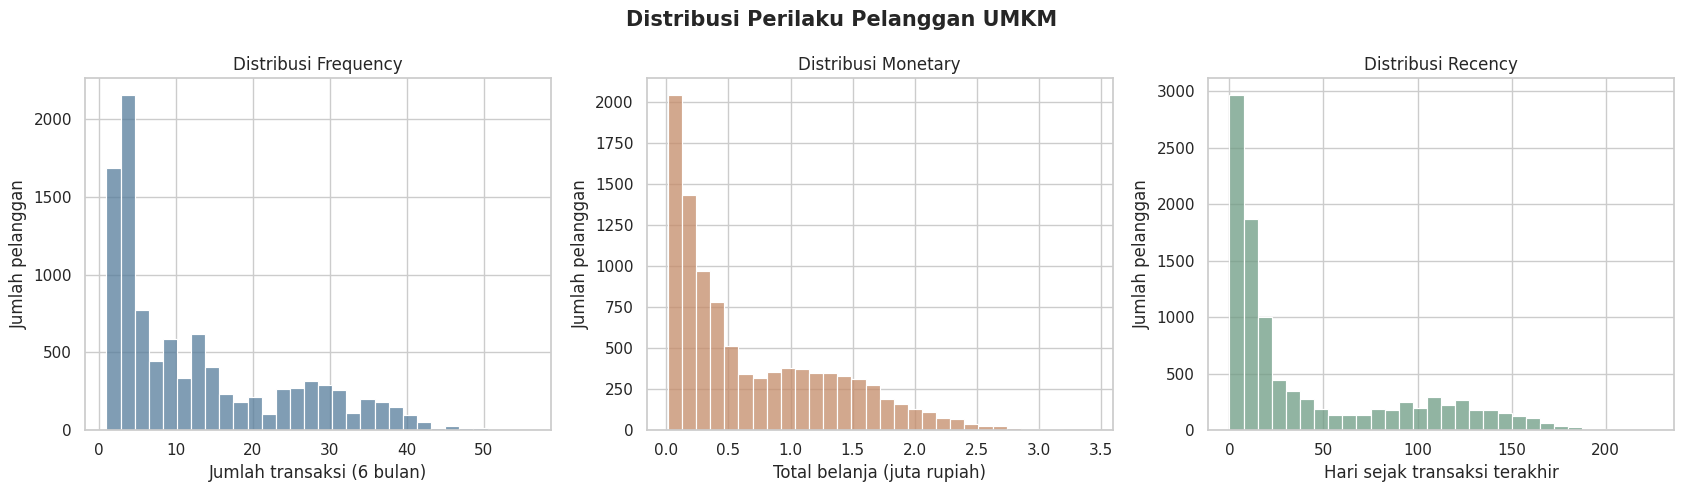

In [13]:

# =====================================================
# 13. EDA - VISUALISASI DISTRIBUSI RFM
# =====================================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    1, 3, figsize=(17, 5)
)

# Frequency
sns.histplot(
    data=df_clean,
    x="jumlah_transaksi_6bln",
    bins=30,
    color="#557C9B",
    ax=axes[0]
)
axes[0].set_title("Distribusi Frequency")
axes[0].set_xlabel("Jumlah transaksi (6 bulan)")
axes[0].set_ylabel("Jumlah pelanggan")

# Monetary (dikonversi menjadi juta rupiah
# untuk visualisasi saja)
belanja_juta = df_clean["total_belanja_rp"] / 1_000_000

sns.histplot(
    x=belanja_juta,
    bins=30,
    color="#C48B68",
    ax=axes[1]
)
axes[1].set_title("Distribusi Monetary")
axes[1].set_xlabel("Total belanja (juta rupiah)")
axes[1].set_ylabel("Jumlah pelanggan")

# Recency
sns.histplot(
    data=df_clean,
    x="hari_sejak_transaksi_terakhir",
    bins=30,
    color="#6D9B83",
    ax=axes[2]
)
axes[2].set_title("Distribusi Recency")
axes[2].set_xlabel("Hari sejak transaksi terakhir")
axes[2].set_ylabel("Jumlah pelanggan")

plt.suptitle(
    "Distribusi Perilaku Pelanggan UMKM",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [14]:

# =====================================================
# 14. SIMPAN CHECKPOINT DATA CLEANING
# =====================================================

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

folder_proyek = Path(
    "/content/drive/MyDrive/ML_P4P5_Segmentasi_UMKM"
)

folder_data = folder_proyek / "data"
folder_data.mkdir(parents=True, exist_ok=True)

path_clean = folder_data / "cleaned_customers.csv"

df_clean.to_csv(
    path_clean,
    index=False,
    date_format="%Y-%m-%d"
)

print("Data bersih tersimpan di:")
print(path_clean)


Mounted at /content/drive
Data bersih tersimpan di:
/content/drive/MyDrive/ML_P4P5_Segmentasi_UMKM/data/cleaned_customers.csv



### Interpretasi Distribusi RFM

Berdasarkan hasil EDA terhadap 10.000 pelanggan, ketiga variabel RFM memperlihatkan kecenderungan distribusi menceng ke kanan (*right-skewed*).

**Frequency:** Rata-rata transaksi sebesar 12,54, sedangkan median sebesar 8 transaksi. Hal ini menunjukkan adanya perbedaan tingkat frekuensi pembelian antarpelanggan.

**Monetary:** Rata-rata pengeluaran pelanggan mencapai Rp693.711, lebih tinggi daripada median Rp425.050. Kondisi ini menunjukkan bahwa sebagian pelanggan memiliki nilai belanja jauh lebih besar dibandingkan pelanggan pada umumnya.

**Recency:** Median recency sebesar 15 hari, sedangkan rata-ratanya 41,76 hari. Hal ini menunjukkan bahwa meskipun banyak pelanggan bertransaksi relatif baru, terdapat pula pelanggan dengan jeda transaksi yang jauh lebih panjang.

**Implikasi preprocessing:** Perbedaan distribusi dan skala antarfitur perlu diperhatikan sebelum menggunakan K-Means. Transformasi logaritmik dan scaling akan dievaluasi melalui eksperimen, bukan diterapkan secara otomatis.

Hasil EDA belum digunakan untuk menentukan jumlah cluster.



## 5. Pembagian Data

Dataset dibagi menjadi training (70%), validation (15%), dan test (15%) secara reproducible.

- **Training:** untuk EDA lanjutan, fitting preprocessing, dan pelatihan K-Means.
- **Validation:** untuk membandingkan konfigurasi dan memilih model.
- **Test:** disimpan tanpa digunakan untuk tuning hingga evaluasi final.

Karena clustering merupakan unsupervised learning, pembagian dilakukan tanpa stratifikasi label target.

EDA deskriptif awal telah dilakukan pada seluruh data sebelum pembagian. Setelah tahap ini, keputusan pemodelan didasarkan pada data training dan validation, bukan test.


In [15]:

# =====================================================
# 15. TRAIN / VALIDATION / TEST SPLIT
# =====================================================

from sklearn.model_selection import train_test_split

# Pisahkan 15% untuk test
df_train_val, df_test = train_test_split(
    df_clean,
    test_size=0.15,
    random_state=RANDOM_STATE,
    shuffle=True
)

# Pisahkan validation dari sisa 85%
# 15/85 menghasilkan 15% dari keseluruhan data
df_train, df_val = train_test_split(
    df_train_val,
    test_size=15/85,
    random_state=RANDOM_STATE,
    shuffle=True
)

# Rapikan indeks
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print("=== PEMBAGIAN DATA ===")
print("Training  :", df_train.shape)
print("Validation:", df_val.shape)
print("Test      :", df_test.shape)

print("\nTotal baris:",
      len(df_train) + len(df_val) + len(df_test))

# Periksa tidak ada ID pelanggan yang tumpang tindih
train_ids = set(df_train["id_pelanggan"])
val_ids = set(df_val["id_pelanggan"])
test_ids = set(df_test["id_pelanggan"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(df_train) + len(df_val) + len(df_test) == len(df_clean)

print("\nVALIDASI SPLIT BERHASIL!")
print("Tidak ada pelanggan yang muncul di dua subset.")


=== PEMBAGIAN DATA ===
Training  : (7000, 15)
Validation: (1500, 15)
Test      : (1500, 15)

Total baris: 10000

VALIDASI SPLIT BERHASIL!
Tidak ada pelanggan yang muncul di dua subset.



### 5.1 EDA Lanjutan pada Data Training

Eksplorasi lanjutan dilakukan hanya menggunakan 7.000 data training untuk menjaga independensi data evaluasi.

Analisis mencakup:
1. Korelasi antara Recency, Frequency, dan Monetary.
2. Hubungan penggunaan promo dengan perilaku pelanggan.
3. Identifikasi outlier menggunakan metode IQR.
4. Pemeriksaan jumlah anomali yang telah ditandai.

Hasil analisis digunakan sebagai dasar perancangan fitur dan preprocessing sebelum K-Means.


=== KORELASI SPEARMAN ===


,hari_sejak_transaksi_terakhir,jumlah_transaksi_6bln,total_belanja_rp,persen_pakai_promo
hari_sejak_transaksi_terakhir,1.000,-0.803,-0.671,0.054
jumlah_transaksi_6bln,-0.803,1.000,0.770,-0.057
total_belanja_rp,-0.671,0.770,1.000,-0.432
persen_pakai_promo,0.054,-0.057,-0.432,1.000


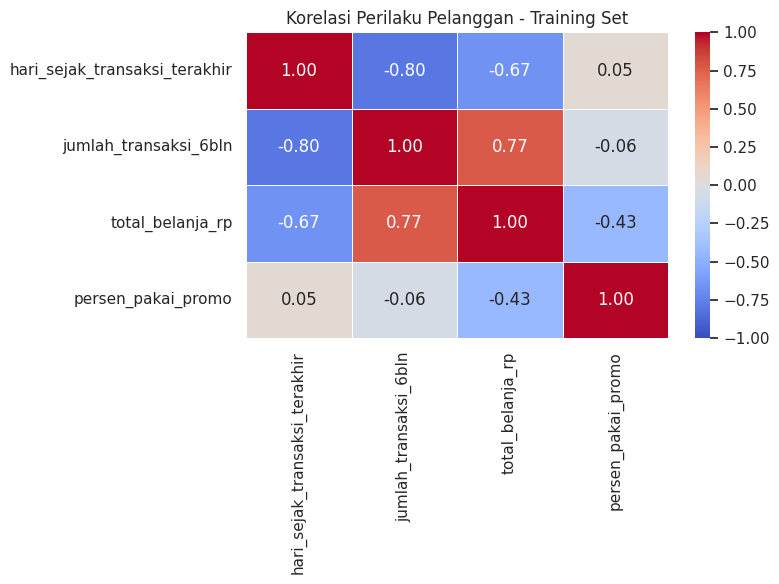

In [16]:

# =====================================================
# 16. EDA TRAINING - ANALISIS KORELASI
# =====================================================

fitur_eda = [
    "hari_sejak_transaksi_terakhir",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "persen_pakai_promo"
]

# Spearman sesuai untuk mengevaluasi hubungan monoton
# dan lebih tahan terhadap nilai ekstrem daripada Pearson.
korelasi = df_train[fitur_eda].corr(
    method="spearman"
)

print("=== KORELASI SPEARMAN ===")
display(korelasi.round(3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    korelasi,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Korelasi Perilaku Pelanggan - Training Set")
plt.tight_layout()
plt.show()


In [17]:

# =====================================================
# 17. EDA TRAINING - OUTLIER DAN ANOMALI
# =====================================================

fitur_numerik = [
    "hari_sejak_transaksi_terakhir",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "persen_pakai_promo"
]

hasil_outlier = []

for kolom in fitur_numerik:
    Q1 = df_train[kolom].quantile(0.25)
    Q3 = df_train[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    mask_outlier = (
        (df_train[kolom] < batas_bawah) |
        (df_train[kolom] > batas_atas)
    )

    jumlah = mask_outlier.sum()

    hasil_outlier.append({
        "fitur": kolom,
        "Q1": Q1,
        "Q3": Q3,
        "batas_bawah": batas_bawah,
        "batas_atas": batas_atas,
        "jumlah_outlier": jumlah,
        "persentase": round(jumlah / len(df_train) * 100, 2)
    })

df_outlier = pd.DataFrame(hasil_outlier)

print("=== DETEKSI OUTLIER METODE IQR ===")
display(df_outlier.round(2))

print("\n=== ANOMALI PADA TRAINING SET ===")

kolom_flag = [
    "flag_umur_perlu_verifikasi",
    "flag_recency_luar_periode",
    "flag_transaksi_sebelum_daftar"
]

audit_train = pd.DataFrame({
    "jumlah": df_train[kolom_flag].sum(),
    "persentase": (
        df_train[kolom_flag].mean() * 100
    ).round(2)
})

display(audit_train)

print("\n=== STATISTIK PENGGUNAAN PROMO ===")
display(
    df_train["persen_pakai_promo"]
    .describe()
    .round(2)
)


=== DETEKSI OUTLIER METODE IQR ===


,fitur,Q1,Q3,batas_bawah,batas_atas,jumlah_outlier,persentase
0,hari_sejak_transaksi_terakhir,6.0,72.0,-93.0,171.0,65,0.93
1,jumlah_transaksi_6bln,3.0,21.0,-24.0,48.0,13,0.19
2,total_belanja_rp,154000.0,1141525.0,-1327287.5,2622812.5,43,0.61
3,persen_pakai_promo,16.0,67.0,-60.5,143.5,0,0.00



=== ANOMALI PADA TRAINING SET ===


,jumlah,persentase
flag_umur_perlu_verifikasi,69,0.99
flag_recency_luar_periode,37,0.53
flag_transaksi_sebelum_daftar,199,2.84



=== STATISTIK PENGGUNAAN PROMO ===


,persen_pakai_promo
count,7000.00
mean,38.76
std,28.16
min,0.00
25%,16.00
50%,28.00
75%,67.00
max,100.00


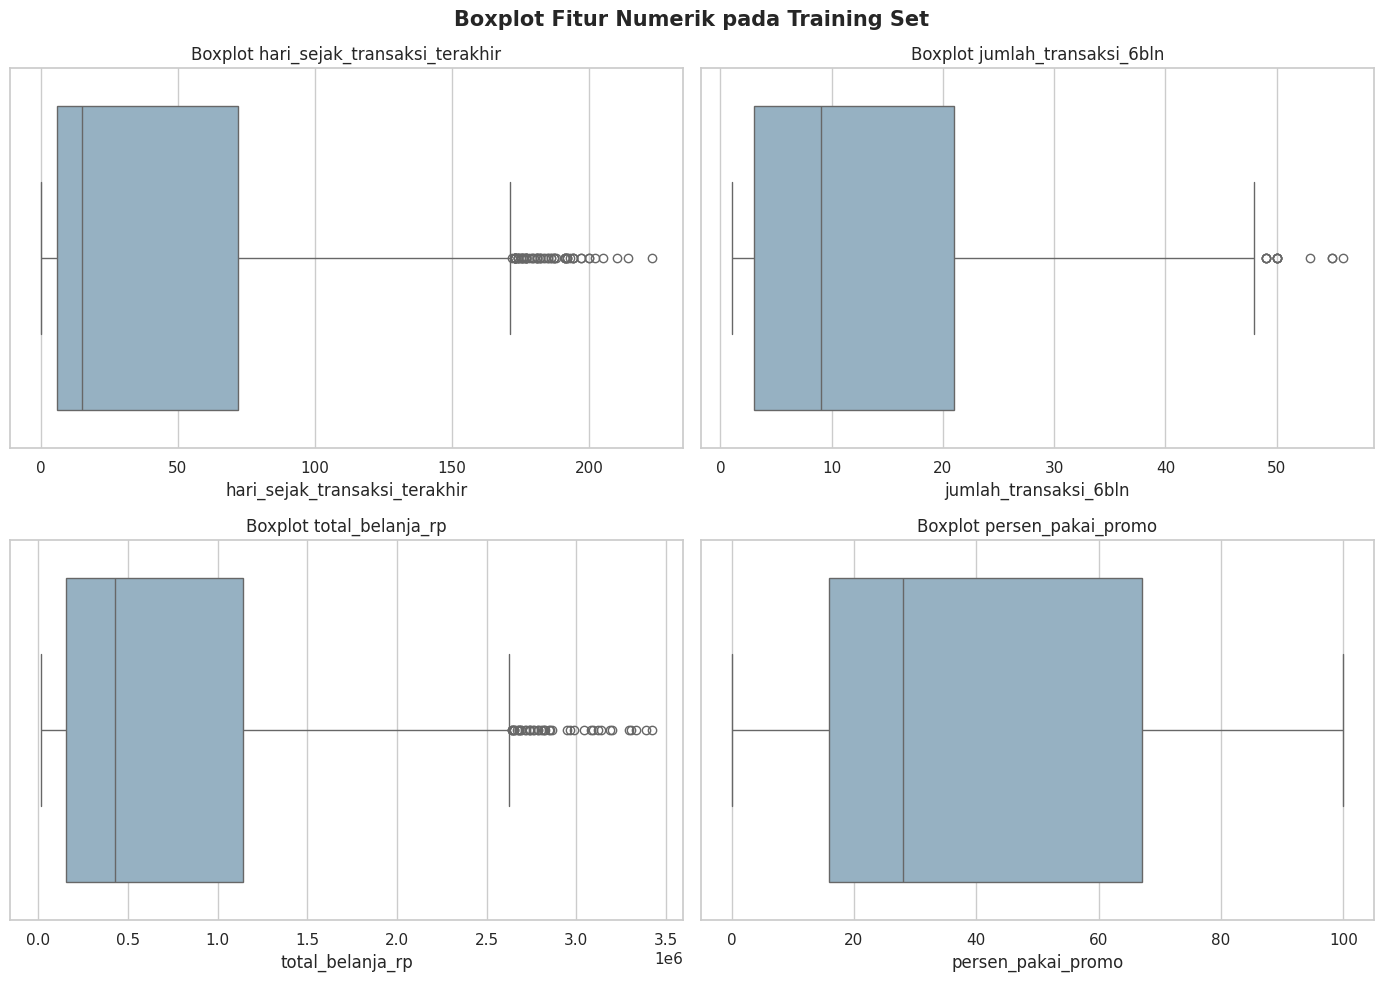

In [19]:
# =====================================================
# 17B. EDA TRAINING - BOXPLOT OUTLIER
# =====================================================

import matplotlib.pyplot as plt
import seaborn as sns

fitur_boxplot = [
    "hari_sejak_transaksi_terakhir",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "persen_pakai_promo"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, kolom in enumerate(fitur_boxplot):
    sns.boxplot(
        x=df_train[kolom],
        ax=axes[i],
        color="#8FB3C9"
    )
    axes[i].set_title(f"Boxplot {kolom}")
    axes[i].set_xlabel(kolom)

plt.suptitle(
    "Boxplot Fitur Numerik pada Training Set",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

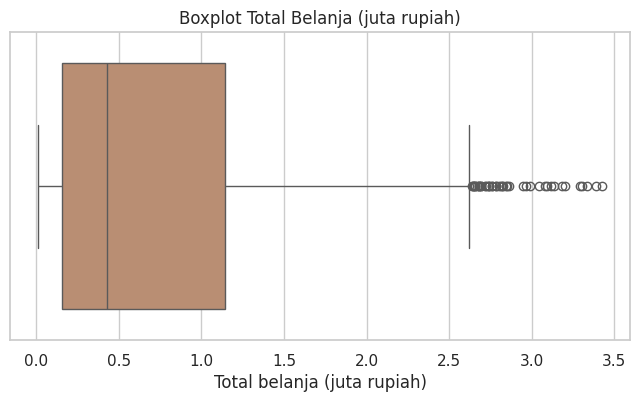

In [20]:
# =====================================================
# 17C. BOXPLOT TOTAL BELANJA DALAM JUTA RUPIAH
# =====================================================

plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df_train["total_belanja_rp"] / 1_000_000,
    color="#C48B68"
)

plt.title("Boxplot Total Belanja (juta rupiah)")
plt.xlabel("Total belanja (juta rupiah)")
plt.show()


### Interpretasi Korelasi dan Outlier

Analisis korelasi Spearman pada 7.000 data training menunjukkan hubungan negatif kuat antara Recency dan Frequency (ρ = −0,803), serta hubungan positif kuat antara Frequency dan Monetary (ρ = 0,770).

Temuan tersebut mengindikasikan bahwa pelanggan dengan frekuensi transaksi tinggi cenderung memiliki aktivitas pembelian yang lebih baru dan total pengeluaran lebih tinggi. Korelasi ini tidak menunjukkan hubungan sebab-akibat.

Analisis boxplot dan metode IQR menemukan 65 outlier Recency (0,93%), 13 outlier Frequency (0,19%), dan 43 outlier Monetary (0,61%). Tidak ditemukan outlier pada persentase penggunaan promo berdasarkan batas IQR.

Outlier tidak langsung dihapus karena dapat merepresentasikan karakteristik pelanggan yang bernilai secara bisnis.

Sebanyak 37 data training memiliki Recency di luar periode pengamatan, sedangkan 199 data memiliki indikasi transaksi terakhir sebelum tanggal pendaftaran. Anomali ini tetap didokumentasikan dan akan dipertimbangkan dalam analisis sensitivitas.

Untuk baseline K-Means, digunakan fitur Recency, Frequency, dan Monetary. Scaling dilakukan dalam pipeline model dengan fitting hanya pada data training. Transformasi logaritmik dan penambahan fitur penggunaan promo akan dievaluasi pada eksperimen berikutnya.


In [21]:

# =====================================================
# 18. FEATURE SELECTION - BASELINE RFM
# =====================================================

FEATURES_RFM = [
    "hari_sejak_transaksi_terakhir",
    "jumlah_transaksi_6bln",
    "total_belanja_rp"
]

# Ambil fitur hanya dari training dan validation
X_train_rfm = df_train[FEATURES_RFM].copy()
X_val_rfm = df_val[FEATURES_RFM].copy()

# Pastikan fitur numerik
X_train_rfm = X_train_rfm.astype("float64")
X_val_rfm = X_val_rfm.astype("float64")

# Validasi kualitas fitur
assert X_train_rfm.notna().all().all()
assert X_val_rfm.notna().all().all()

assert (X_train_rfm >= 0).all().all()
assert (X_val_rfm >= 0).all().all()

assert list(X_train_rfm.columns) == FEATURES_RFM
assert list(X_val_rfm.columns) == FEATURES_RFM

print("=== FITUR BASELINE K-MEANS ===")
print(FEATURES_RFM)

print("\n=== UKURAN DATA ===")
print("Training  :", X_train_rfm.shape)
print("Validation:", X_val_rfm.shape)

print("\n=== STATISTIK FITUR TRAINING ===")
display(X_train_rfm.describe().round(2))

print("\nVALIDASI FITUR RFM BERHASIL!")


=== FITUR BASELINE K-MEANS ===
['hari_sejak_transaksi_terakhir', 'jumlah_transaksi_6bln', 'total_belanja_rp']

=== UKURAN DATA ===
Training  : (7000, 3)
Validation: (1500, 3)

=== STATISTIK FITUR TRAINING ===


,hari_sejak_transaksi_terakhir,jumlah_transaksi_6bln,total_belanja_rp
count,7000.00,7000.00,7000.00
mean,40.98,12.67,691550.86
std,48.89,11.64,643794.89
min,0.00,1.00,11900.00
25%,6.00,3.00,154000.00
50%,15.00,9.00,427600.00
75%,72.00,21.00,1141525.00
max,223.00,56.00,3424200.00



VALIDASI FITUR RFM BERHASIL!


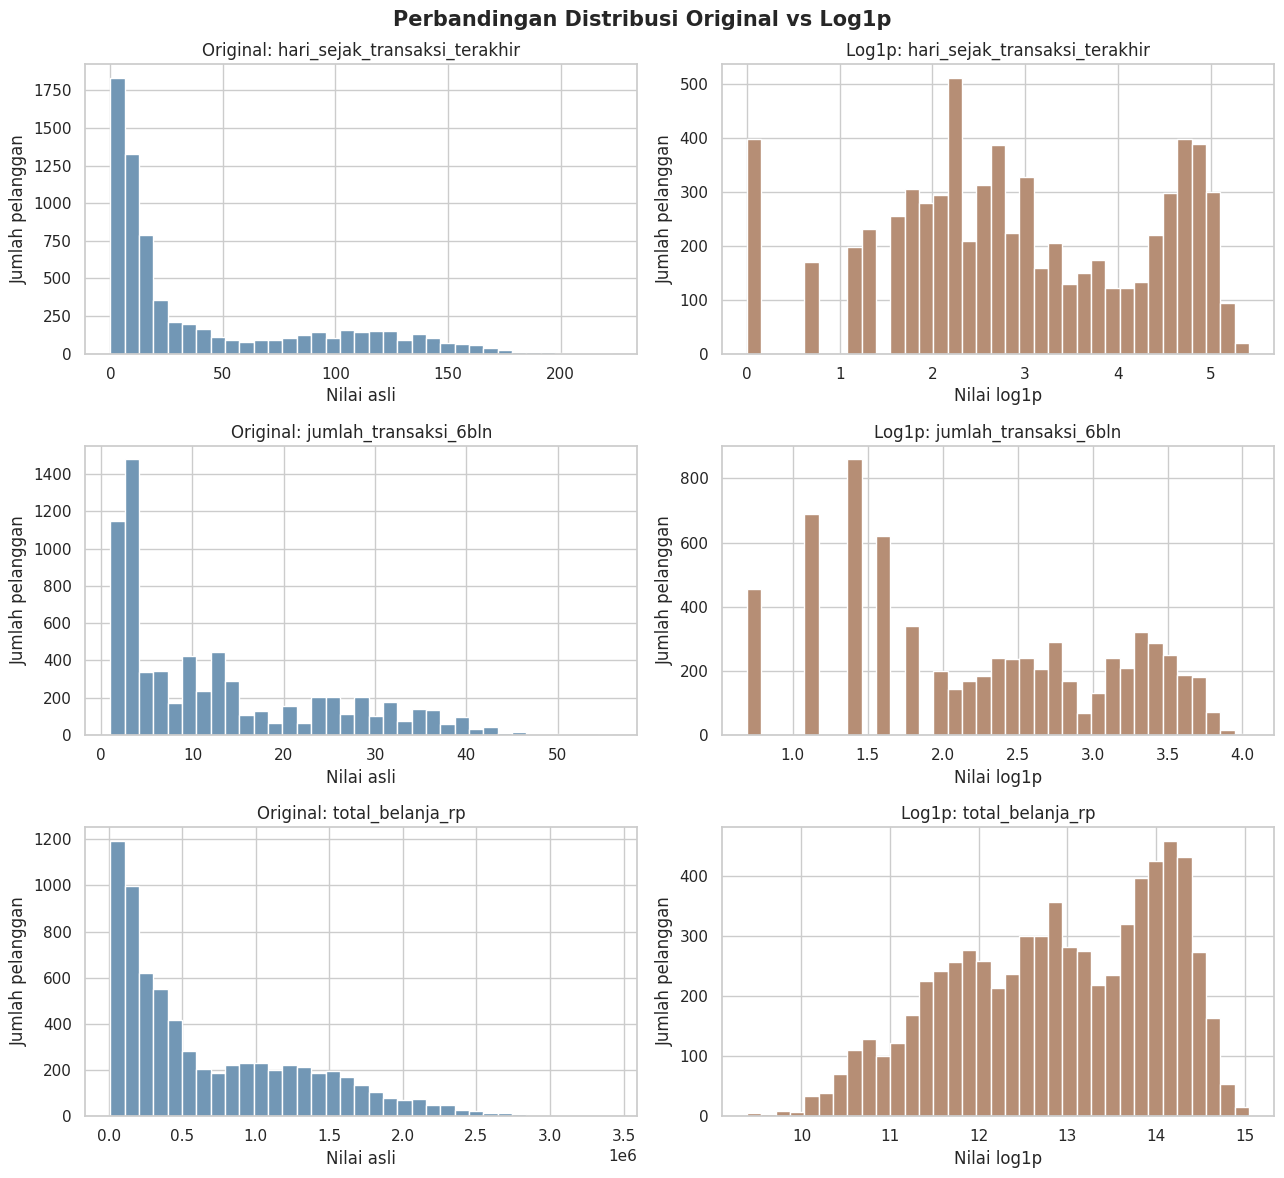

=== PERBANDINGAN SKEWNESS ===


,fitur,skew_original,skew_log1p
0,hari_sejak_transaksi_terakhir,1.218,-0.163
1,jumlah_transaksi_6bln,0.994,0.038
2,total_belanja_rp,1.024,-0.366


In [22]:

# =====================================================
# 19. DIAGNOSTIK TRANSFORMASI LOG1P
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

fitur_log = FEATURES_RFM

fig, axes = plt.subplots(
    3, 2, figsize=(13, 12)
)

for i, kolom in enumerate(fitur_log):
    data_asli = X_train_rfm[kolom]
    data_log = np.log1p(data_asli)

    axes[i, 0].hist(
        data_asli, bins=35,
        color="#7297B5", edgecolor="white"
    )
    axes[i, 0].set_title(f"Original: {kolom}")
    axes[i, 0].set_xlabel("Nilai asli")
    axes[i, 0].set_ylabel("Jumlah pelanggan")

    axes[i, 1].hist(
        data_log, bins=35,
        color="#B68E75", edgecolor="white"
    )
    axes[i, 1].set_title(f"Log1p: {kolom}")
    axes[i, 1].set_xlabel("Nilai log1p")
    axes[i, 1].set_ylabel("Jumlah pelanggan")

plt.suptitle(
    "Perbandingan Distribusi Original vs Log1p",
    fontsize=15, fontweight="bold"
)
plt.tight_layout()
plt.show()

# Bandingkan skewness
hasil_skew = pd.DataFrame({
    "fitur": fitur_log,
    "skew_original": [
        X_train_rfm[k].skew() for k in fitur_log
    ],
    "skew_log1p": [
        np.log1p(X_train_rfm[k]).skew()
        for k in fitur_log
    ]
})

print("=== PERBANDINGAN SKEWNESS ===")
display(hasil_skew.round(3))



### Interpretasi Transformasi Log1p

Hasil analisis pada data training menunjukkan bahwa transformasi `log1p` mengurangi kemencengan distribusi seluruh fitur RFM.

Skewness Recency berubah dari 1,218 menjadi -0,163, Frequency dari 0,994 menjadi 0,038, dan Monetary dari 1,024 menjadi -0,366.

Transformasi ini berpotensi mengurangi dominasi nilai besar dan membuat distribusi fitur lebih seimbang. Namun, perubahan bentuk distribusi belum cukup untuk menyimpulkan peningkatan kualitas clustering.

Oleh karena itu, baseline K-Means menggunakan fitur RFM asli dengan StandardScaler. Transformasi `log1p` akan dievaluasi sebagai eksperimen improvement menggunakan data training dan validation.



## 6. Baseline Modeling — K-Means Clustering

### 6.1 Tujuan

Membangun baseline segmentasi pelanggan menggunakan K-Means berdasarkan tiga fitur RFM:

1. `hari_sejak_transaksi_terakhir`
2. `jumlah_transaksi_6bln`
3. `total_belanja_rp`

### 6.2 Metodologi

- Algoritma: K-Means
- Preprocessing: StandardScaler
- Eksperimen jumlah cluster: k = 2 hingga 8
- Random state: 42
- Evaluasi: silhouette, inertia, dan distribusi ukuran cluster
- Training: 7.000 pelanggan
- Validation: 1.500 pelanggan

StandardScaler dan K-Means digabungkan menggunakan Scikit-learn Pipeline agar preprocessing pada data validation menggunakan parameter yang dipelajari dari data training.

Test set tidak digunakan pada tahap ini.


In [23]:

# =====================================================
# 20. BASELINE K-MEANS - EVALUASI BERBAGAI K
# =====================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import pandas as pd
import numpy as np

K_VALUES = range(2, 9)

hasil_baseline = []
model_baseline = {}

for k in K_VALUES:

    # Pipeline: scaling lalu clustering
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        ))
    ])

    # Fit hanya pada training
    pipeline.fit(X_train_rfm)

    # Prediksi cluster training dan validation
    label_train = pipeline.predict(X_train_rfm)
    label_val = pipeline.predict(X_val_rfm)

    # Transformasi menggunakan scaler training
    X_train_scaled = pipeline.named_steps[
        "scaler"
    ].transform(X_train_rfm)

    X_val_scaled = pipeline.named_steps[
        "scaler"
    ].transform(X_val_rfm)

    # Silhouette training memakai sampel tetap
    silhouette_train = silhouette_score(
        X_train_scaled,
        label_train,
        sample_size=1500,
        random_state=RANDOM_STATE
    )

    # Validation dievaluasi tanpa refitting
    silhouette_val = silhouette_score(
        X_val_scaled,
        label_val
    )

    # Inertia hanya dari training
    inertia = pipeline.named_steps[
        "kmeans"
    ].inertia_

    # Distribusi cluster validation
    ukuran_cluster = pd.Series(
        label_val
    ).value_counts()

    cluster_terkecil = ukuran_cluster.min()
    persen_terkecil = (
        cluster_terkecil / len(label_val) * 100
    )

    hasil_baseline.append({
        "k": k,
        "silhouette_train": silhouette_train,
        "silhouette_val": silhouette_val,
        "inertia_train": inertia,
        "cluster_terkecil_val": cluster_terkecil,
        "persen_cluster_terkecil": persen_terkecil
    })

    model_baseline[k] = pipeline

    print(f"k={k} selesai")

df_baseline = pd.DataFrame(hasil_baseline)

print("\n=== HASIL BASELINE K-MEANS ===")
display(df_baseline.round(4))


k=2 selesai
k=3 selesai
k=4 selesai
k=5 selesai
k=6 selesai
k=7 selesai
k=8 selesai

=== HASIL BASELINE K-MEANS ===


,k,silhouette_train,silhouette_val,inertia_train,cluster_terkecil_val,persen_cluster_terkecil
0,2,0.4652,0.4751,10293.8648,451,30.0667
1,3,0.5366,0.5423,4880.9357,366,24.4000
2,4,0.5525,0.5619,3569.5144,174,11.6000
3,5,0.5282,0.5300,2698.0343,172,11.4667
4,6,0.4938,0.4811,2154.9665,169,11.2667
5,7,0.4861,0.4698,1833.4595,87,5.8000
6,8,0.4616,0.4538,1561.1806,83,5.5333


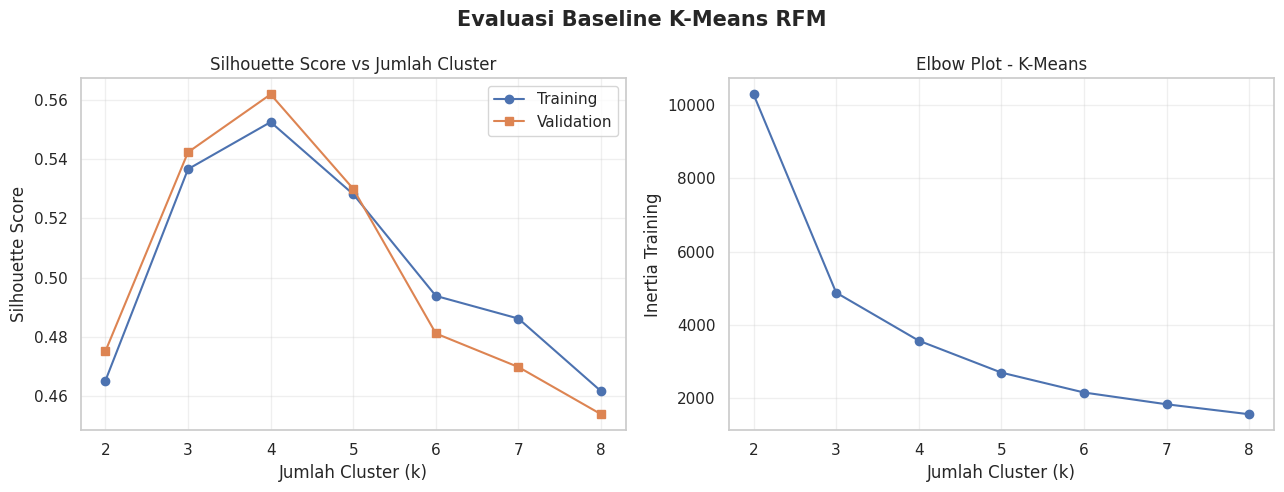

In [24]:

# =====================================================
# 21. VISUALISASI EVALUASI BASELINE
# =====================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik silhouette
axes[0].plot(
    df_baseline["k"],
    df_baseline["silhouette_train"],
    marker="o",
    label="Training"
)

axes[0].plot(
    df_baseline["k"],
    df_baseline["silhouette_val"],
    marker="s",
    label="Validation"
)

axes[0].set_title("Silhouette Score vs Jumlah Cluster")
axes[0].set_xlabel("Jumlah Cluster (k)")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_xticks(list(K_VALUES))
axes[0].legend()
axes[0].grid(alpha=0.3)

# Elbow plot
axes[1].plot(
    df_baseline["k"],
    df_baseline["inertia_train"],
    marker="o"
)

axes[1].set_title("Elbow Plot - K-Means")
axes[1].set_xlabel("Jumlah Cluster (k)")
axes[1].set_ylabel("Inertia Training")
axes[1].set_xticks(list(K_VALUES))
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Evaluasi Baseline K-Means RFM",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 6.3 Interpretasi Hasil Baseline

Eksperimen K-Means dilakukan untuk k=2 hingga k=8 menggunakan fitur RFM asli yang distandardisasi dengan StandardScaler.

Nilai silhouette validation tertinggi diperoleh pada **k=4 sebesar 0,5619**, sedangkan silhouette training sebesar 0,5525. Hasil ini menunjukkan pemisahan cluster yang relatif baik pada representasi fitur yang digunakan.

Elbow Plot memperlihatkan penurunan inertia yang semakin melandai ketika jumlah cluster meningkat. Jumlah cluster k=4 menjadi kandidat baseline karena memberikan keseimbangan antara silhouette, ukuran cluster, dan kompleksitas segmentasi.

Pada validation set, cluster terkecil berisi 174 pelanggan (11,6%), sehingga tidak ditemukan kelompok dengan ukuran sangat kecil pada konfigurasi tersebut.

Namun, k=4 belum ditetapkan sebagai model final. Interpretasi statistik, relevansi bisnis, stabilitas, dan hasil eksperimen improvement tetap perlu diperiksa. Konfigurasi k=3 juga dapat dijadikan pembanding.



## 7. Customer Profiling — Baseline K-Means

### 7.1 Tujuan

Tahap ini bertujuan menginterpretasikan karakteristik setiap cluster yang dihasilkan oleh baseline K-Means dengan k=4.

Profiling dilakukan menggunakan nilai fitur dalam satuan asli agar hasilnya mudah dipahami secara bisnis.

Variabel yang dianalisis:
- Jumlah dan persentase pelanggan.
- Rata-rata dan median Recency.
- Rata-rata dan median Frequency.
- Rata-rata dan median Monetary.
- Rata-rata penggunaan promo.
- Kategori produk favorit dan kanal pembelian dominan.

Profil pada training dan validation dibandingkan untuk memeriksa konsistensi karakteristik segmen.

Nama segmen belum diberikan sebelum profil aktual diperiksa.


In [25]:

# =====================================================
# 22. CUSTOMER PROFILING - BASELINE K=4
# =====================================================

K_BASELINE = 4
pipeline_k4 = model_baseline[K_BASELINE]

# Salin data, jangan ubah df_train atau df_val
df_train_profile = df_train.copy()
df_val_profile = df_val.copy()

# Prediksi menggunakan model yang sudah dilatih
df_train_profile["cluster"] = pipeline_k4.predict(
    X_train_rfm
)

df_val_profile["cluster"] = pipeline_k4.predict(
    X_val_rfm
)

# Fungsi untuk membuat profil tiap cluster
def buat_profil_cluster(data):

    group = data.groupby("cluster")

    profil = group.agg(
        jumlah_pelanggan=("id_pelanggan", "size"),

        recency_mean=(
            "hari_sejak_transaksi_terakhir", "mean"
        ),
        recency_median=(
            "hari_sejak_transaksi_terakhir", "median"
        ),

        frequency_mean=(
            "jumlah_transaksi_6bln", "mean"
        ),
        frequency_median=(
            "jumlah_transaksi_6bln", "median"
        ),

        monetary_mean=("total_belanja_rp", "mean"),
        monetary_median=("total_belanja_rp", "median"),

        promo_mean=("persen_pakai_promo", "mean")
    )

    # Persentase anggota setiap cluster
    profil["persen_pelanggan"] = (
        profil["jumlah_pelanggan"] / len(data) * 100
    )

    # Kategori produk paling banyak muncul
    profil["kategori_dominan"] = group[
        "kategori_favorit"
    ].agg(lambda s: s.mode().iloc[0])

    # Channel paling banyak muncul
    profil["channel_dominan"] = group[
        "channel_utama"
    ].agg(lambda s: s.mode().iloc[0])

    return profil.round(2).sort_index()


profil_train = buat_profil_cluster(df_train_profile)
profil_val = buat_profil_cluster(df_val_profile)

print("=== PROFIL CLUSTER TRAINING ===")
display(profil_train)

print("\n=== PROFIL CLUSTER VALIDATION ===")
display(profil_val)

print("\n=== VALIDASI JUMLAH PELANGGAN ===")

assert profil_train["jumlah_pelanggan"].sum() == 7000
assert profil_val["jumlah_pelanggan"].sum() == 1500

assert df_train_profile["cluster"].nunique() == 4
assert df_val_profile["cluster"].nunique() == 4

print("Customer profiling berhasil!")


=== PROFIL CLUSTER TRAINING ===


,jumlah_pelanggan,recency_mean,recency_median,frequency_mean,frequency_median,monetary_mean,monetary_median,promo_mean,persen_pelanggan,kategori_dominan,channel_dominan
cluster,,,,,,,,,,,
0,2688,14.77,12.0,10.28,11.0,420490.36,380350.0,60.47,38.40,kopi,toko
1,1912,114.12,113.0,2.57,3.0,106784.0,97550.0,34.64,27.31,kopi,toko
2,655,30.40,30.0,4.66,5.0,1408475.27,1314600.0,12.01,9.36,paket_snack,toko
3,1745,5.20,5.0,30.43,30.0,1480719.54,1418500.0,19.89,24.93,kopi,toko



=== PROFIL CLUSTER VALIDATION ===


,jumlah_pelanggan,recency_mean,recency_median,frequency_mean,frequency_median,monetary_mean,monetary_median,promo_mean,persen_pelanggan,kategori_dominan,channel_dominan
cluster,,,,,,,,,,,
0,541,15.08,13.0,10.09,10.0,408865.06,374600.0,61.40,36.07,kopi,toko
1,440,114.21,111.5,2.54,3.0,108103.41,100850.0,35.38,29.33,kopi,toko
2,174,32.10,31.5,4.59,5.0,1400332.76,1303050.0,13.21,11.60,kue_ulang_tahun,toko
3,345,5.34,5.0,30.51,30.0,1541817.68,1474600.0,20.02,23.00,kopi,toko



=== VALIDASI JUMLAH PELANGGAN ===
Customer profiling berhasil!


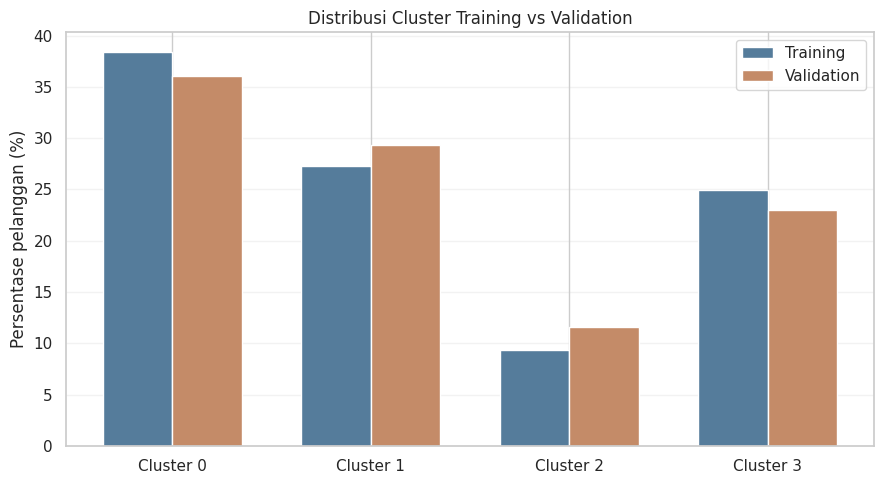

In [26]:

# =====================================================
# 23. VISUALISASI DISTRIBUSI CLUSTER
# =====================================================

import matplotlib.pyplot as plt
import numpy as np

clusters = profil_train.index

train_pct = profil_train["persen_pelanggan"]
val_pct = profil_val.reindex(clusters)["persen_pelanggan"]

x = np.arange(len(clusters))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    train_pct,
    width,
    label="Training",
    color="#557C9B"
)

ax.bar(
    x + width / 2,
    val_pct,
    width,
    label="Validation",
    color="#C48B68"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"Cluster {i}" for i in clusters]
)

ax.set_ylabel("Persentase pelanggan (%)")
ax.set_title("Distribusi Cluster Training vs Validation")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()



### 7.2 Analisis Kategori Produk dan Nilai Transaksi

Analisis lanjutan dilakukan untuk memvalidasi interpretasi bisnis setiap cluster.

Pemeriksaan meliputi:
1. Distribusi persentase kategori favorit pada tiap cluster.
2. Distribusi kanal pembelian.
3. Rata-rata nominal per transaksi berdasarkan total agregat.
4. Konsistensi profil antara training dan validation.

Analisis ini diperlukan karena kategori dominan saja belum cukup untuk menggambarkan keseluruhan preferensi pelanggan.

Hasilnya digunakan untuk merumuskan nama segmen sementara, bukan untuk mengubah label target karena clustering tidak memiliki ground truth.


In [27]:

# =====================================================
# 24. BUSINESS PROFILING - KATEGORI & NILAI TRANSAKSI
# =====================================================

def analisis_bisnis_cluster(data, nama_dataset):

    print(f"\n========== {nama_dataset} ==========")

    # A. Distribusi kategori favorit per cluster
    kategori_pct = pd.crosstab(
        data["cluster"],
        data["kategori_favorit"],
        normalize="index"
    ) * 100

    print("\n=== DISTRIBUSI KATEGORI FAVORIT (%) ===")
    display(kategori_pct.round(2))

    # B. Distribusi channel pembelian per cluster
    channel_pct = pd.crosstab(
        data["cluster"],
        data["channel_utama"],
        normalize="index"
    ) * 100

    print("\n=== DISTRIBUSI CHANNEL (%) ===")
    display(channel_pct.round(2))

    # C. Persentase kategori pembelian acara
    kategori_acara = [
        "kue_ulang_tahun",
        "paket_snack"
    ]

    data_temp = data.copy()

    data_temp["pembelian_acara"] = (
        data_temp["kategori_favorit"]
        .isin(kategori_acara)
    )

    porsi_acara = (
        data_temp.groupby("cluster")["pembelian_acara"]
        .mean() * 100
    )

    print("\n=== PERSENTASE KATEGORI ACARA ===")
    display(
        porsi_acara.round(2)
        .rename("persen_kategori_acara")
        .to_frame()
    )

    # D. Nominal rata-rata per transaksi agregat
    ringkasan = data.groupby("cluster").agg(
        total_belanja=("total_belanja_rp", "sum"),
        total_transaksi=("jumlah_transaksi_6bln", "sum")
    )

    ringkasan["rupiah_per_transaksi"] = (
        ringkasan["total_belanja"] /
        ringkasan["total_transaksi"]
    )

    print("\n=== NILAI RATA-RATA PER TRANSAKSI ===")
    display(ringkasan.round(2))

    return kategori_pct, channel_pct, porsi_acara


kategori_train, channel_train, acara_train = (
    analisis_bisnis_cluster(
        df_train_profile,
        "TRAINING"
    )
)

kategori_val, channel_val, acara_val = (
    analisis_bisnis_cluster(
        df_val_profile,
        "VALIDATION"
    )
)



========== TRAINING ==========

=== DISTRIBUSI KATEGORI FAVORIT (%) ===


kategori_favorit,kopi,kue_ulang_tahun,paket_snack,roti
cluster,,,,
0,38.84,11.05,12.95,37.17
1,45.19,9.68,5.23,39.91
2,5.19,42.29,43.97,8.55
3,54.38,4.70,6.07,34.84



=== DISTRIBUSI CHANNEL (%) ===


channel_utama,gofood,grabfood,shopeefood,toko
cluster,,,,
0,25.67,17.93,23.81,32.59
1,25.42,18.83,16.11,39.64
2,8.70,9.62,19.39,62.29
3,16.39,9.91,5.90,67.79



=== PERSENTASE KATEGORI ACARA ===


,persen_kategori_acara
cluster,
0,24.00
1,14.91
2,86.26
3,10.77


... (6 outputs left out)


=== PERSENTASE KATEGORI ACARA ===


,persen_kategori_acara
cluster,
0,23.48
1,15.68
2,83.33
3,10.14



=== NILAI RATA-RATA PER TRANSAKSI ===


,total_belanja,total_transaksi,rupiah_per_transaksi
cluster,,,
0,221196000,5459,40519.51
1,47565500,1119,42507.15
2,243657900,799,304953.57
3,531927100,10527,50529.79


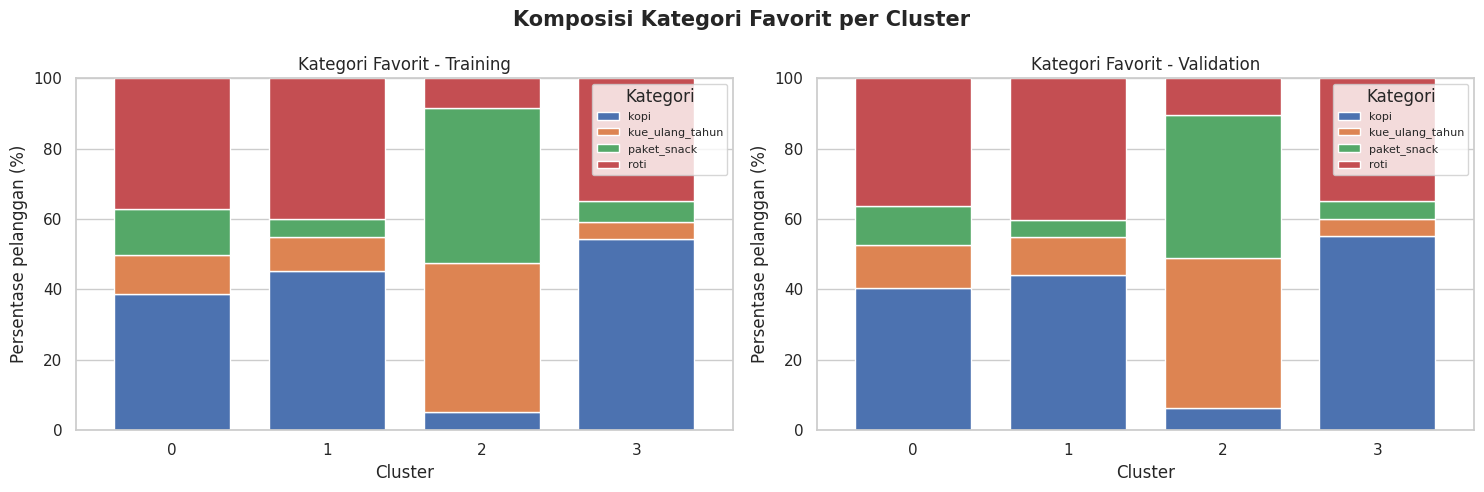

In [28]:

# =====================================================
# 25. VISUALISASI KATEGORI FAVORIT PER CLUSTER
# =====================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, kategori, judul in zip(
    axes,
    [kategori_train, kategori_val],
    ["Training", "Validation"]
):
    kategori.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        width=0.75
    )

    ax.set_title(f"Kategori Favorit - {judul}")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Persentase pelanggan (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(
        title="Kategori",
        fontsize=8,
        loc="upper right"
    )

plt.suptitle(
    "Komposisi Kategori Favorit per Cluster",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 7.3 Interpretasi Profil Bisnis Baseline

Analisis kategori favorit dan nominal per transaksi menunjukkan empat karakteristik pelanggan yang berbeda.

Cluster 0 memiliki aktivitas pembelian relatif rutin dengan penggunaan promo tinggi (60,47%) sehingga sementara diinterpretasikan sebagai pelanggan aktif berorientasi promo.

Cluster 1 menunjukkan frekuensi transaksi rendah dan recency tinggi sehingga menjadi kandidat kelompok pelanggan kurang aktif.

Cluster 2 memiliki karakteristik khusus: 86,26% anggota training menyukai kategori kue ulang tahun atau paket snack dan rata-rata nominal per transaksi agregat mencapai Rp302.080. Pola tersebut juga konsisten pada validation.

Cluster 3 memiliki rata-rata 30,43 transaksi selama enam bulan dengan recency 5,20 hari dan total belanja rata-rata Rp1.480.720, sehingga diinterpretasikan sebagai pelanggan aktif bernilai tinggi.

Hasil profiling menunjukkan bahwa segmentasi tidak hanya memisahkan pelanggan secara matematis, tetapi juga menghasilkan kelompok dengan karakteristik bisnis yang berbeda.

Nama segmen masih bersifat sementara hingga pemilihan model final. Kategori favorit merupakan informasi profiling, bukan fitur pembentuk cluster pada baseline.



## 8. Model Improvement

### 8.1 Eksperimen Log1p + StandardScaler + K-Means

Baseline menggunakan fitur RFM asli dengan StandardScaler.

Eksperimen ini menguji transformasi logaritmik sebelum scaling untuk mengurangi pengaruh rentang nilai besar pada perhitungan jarak.

Konfigurasi:
- Fitur: Recency, Frequency, Monetary
- Transformasi: log1p
- Scaling: StandardScaler
- Algoritma: K-Means
- Jumlah cluster: k=2 hingga k=8
- Random state: 42
- Data: training dan validation

Perbandingan memperhatikan silhouette, ukuran cluster, dan interpretabilitas bisnis.

Karena transformasi mengubah geometri ruang fitur, nilai silhouette antarmetode tidak sepenuhnya setara. Evaluasi akhir tidak hanya didasarkan pada satu angka.


In [29]:

# =====================================================
# 26. MODEL IMPROVEMENT - LOG1P + STANDARD SCALER
# =====================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import numpy as np
import pandas as pd

hasil_log1p = []
model_log1p = {}

K_VALUES = range(2, 9)

for k in K_VALUES:

    # 1. Membuat pipeline eksperimen
    pipeline = Pipeline([
        ("log1p", FunctionTransformer(
            np.log1p,
            validate=False
        )),
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        ))
    ])

    # 2. Fit hanya menggunakan training
    pipeline.fit(X_train_rfm)

    # 3. Prediksi training dan validation
    label_train = pipeline.predict(X_train_rfm)
    label_val = pipeline.predict(X_val_rfm)

    # 4. Representasi fitur setelah log dan scaling
    X_train_transformed = pipeline[:-1].transform(
        X_train_rfm
    )
    X_val_transformed = pipeline[:-1].transform(
        X_val_rfm
    )

    # 5. Evaluasi silhouette
    score_train = silhouette_score(
        X_train_transformed,
        label_train,
        sample_size=1500,
        random_state=RANDOM_STATE
    )

    score_val = silhouette_score(
        X_val_transformed,
        label_val
    )

    # 6. Ukuran cluster validation
    ukuran_cluster = pd.Series(
        label_val
    ).value_counts()

    # 7. Simpan hasil eksperimen
    hasil_log1p.append({
        "k": k,
        "silhouette_train": score_train,
        "silhouette_val": score_val,
        "inertia_train": (
            pipeline.named_steps["kmeans"].inertia_
        ),
        "cluster_terkecil_val": ukuran_cluster.min(),
        "persen_cluster_terkecil": (
            ukuran_cluster.min() / len(label_val) * 100
        )
    })

    model_log1p[k] = pipeline

    print(f"Improvement k={k} selesai")

df_log1p = pd.DataFrame(hasil_log1p)

print("\n=== HASIL IMPROVEMENT LOG1P ===")
display(df_log1p.round(4))

print("\n=== K TERBAIK BERDASARKAN SILHOUETTE VALIDATION ===")
display(
    df_log1p.nlargest(
        3, "silhouette_val"
    ).round(4)
)


Improvement k=2 selesai
Improvement k=3 selesai
Improvement k=4 selesai
Improvement k=5 selesai
Improvement k=6 selesai
Improvement k=7 selesai
Improvement k=8 selesai

=== HASIL IMPROVEMENT LOG1P ===


,k,silhouette_train,silhouette_val,inertia_train,cluster_terkecil_val,persen_cluster_terkecil
0,2,0.5141,0.5129,8265.3177,552,36.8000
1,3,0.4736,0.4850,4876.3947,436,29.0667
2,4,0.5181,0.5296,3503.0209,233,15.5333
3,5,0.5220,0.5303,2895.5708,113,7.5333
4,6,0.4664,0.4668,2389.3722,113,7.5333
5,7,0.4499,0.4571,2055.1433,73,4.8667
6,8,0.4166,0.4139,1837.3035,67,4.4667



=== K TERBAIK BERDASARKAN SILHOUETTE VALIDATION ===


,k,silhouette_train,silhouette_val,inertia_train,cluster_terkecil_val,persen_cluster_terkecil
3,5,0.5220,0.5303,2895.5708,113,7.5333
2,4,0.5181,0.5296,3503.0209,233,15.5333
0,2,0.5141,0.5129,8265.3177,552,36.8000


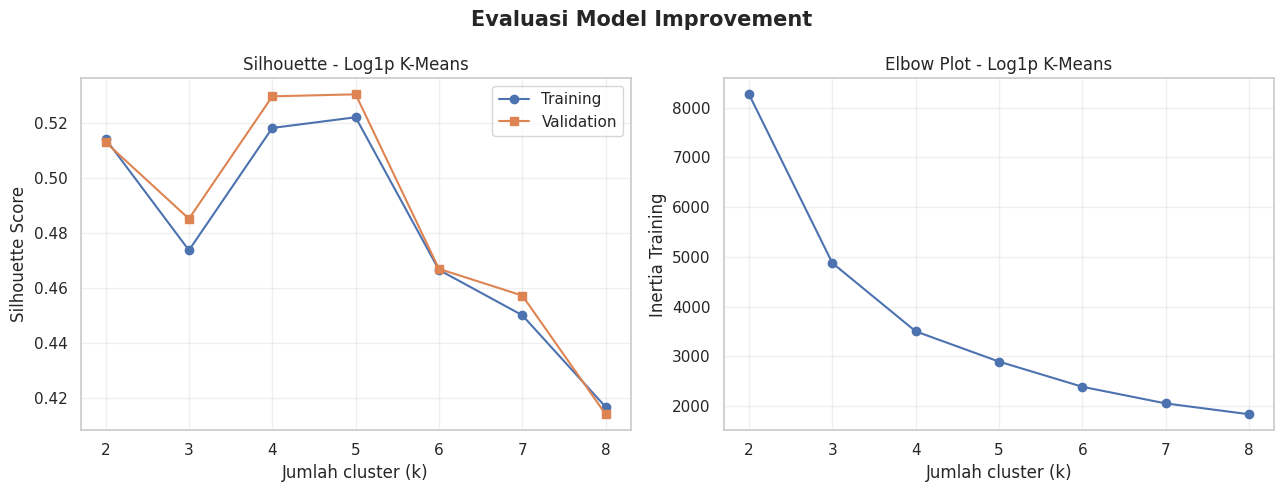

In [30]:

# =====================================================
# 27. VISUALISASI IMPROVEMENT K-MEANS
# =====================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    df_log1p["k"],
    df_log1p["silhouette_train"],
    marker="o",
    label="Training"
)

axes[0].plot(
    df_log1p["k"],
    df_log1p["silhouette_val"],
    marker="s",
    label="Validation"
)

axes[0].set_title("Silhouette - Log1p K-Means")
axes[0].set_xlabel("Jumlah cluster (k)")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_xticks(list(K_VALUES))
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    df_log1p["k"],
    df_log1p["inertia_train"],
    marker="o"
)

axes[1].set_title("Elbow Plot - Log1p K-Means")
axes[1].set_xlabel("Jumlah cluster (k)")
axes[1].set_ylabel("Inertia Training")
axes[1].set_xticks(list(K_VALUES))
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Evaluasi Model Improvement",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 8.2 Interpretasi Hasil Improvement

Eksperimen Log1p + StandardScaler + K-Means dilakukan untuk k=2 hingga k=8.

Nilai silhouette validation tertinggi diperoleh pada k=5 sebesar 0,5303, diikuti k=4 sebesar 0,5296. Perbedaannya hanya 0,0007 sehingga tidak cukup untuk memilih k=5 tanpa mempertimbangkan interpretabilitas dan ukuran cluster.

Baseline RFM asli dengan k=4 menghasilkan silhouette validation sebesar 0,5619. Meskipun transformasi Log1p mengurangi skewness, transformasi tersebut tidak menghasilkan peningkatan silhouette pada konfigurasi yang diuji.

Perbandingan silhouette antartransformasi memiliki keterbatasan karena perhitungan jarak dilakukan pada representasi fitur yang berbeda.

Baseline k=4 tetap menjadi kandidat utama, tetapi keputusan final ditunda sampai evaluasi profil bisnis dan stabilitas model selesai.


In [31]:

# =====================================================
# 28. PROFILING MODEL IMPROVEMENT
# =====================================================

def profil_improvement(pipeline, data):
    # Salinan agar dataset asli tidak berubah
    temp = data.copy()

    # Prediksi dengan pipeline yang sudah di-fit
    temp["cluster"] = pipeline.predict(
        data[FEATURES_RFM]
    )

    # Penanda kategori favorit terkait acara
    temp["kategori_acara"] = temp[
        "kategori_favorit"
    ].isin(["kue_ulang_tahun", "paket_snack"])

    # Statistik setiap cluster
    profil = temp.groupby("cluster").agg(
        jumlah=("id_pelanggan", "size"),
        recency=("hari_sejak_transaksi_terakhir", "mean"),
        frequency=("jumlah_transaksi_6bln", "mean"),
        monetary=("total_belanja_rp", "mean"),
        promo=("persen_pakai_promo", "mean"),
        persen_acara=("kategori_acara", "mean")
    )

    profil["persen_pelanggan"] = (
        profil["jumlah"] / len(temp) * 100
    )

    profil["persen_acara"] *= 100

    # Rasio agregat total belanja per transaksi
    agregat = temp.groupby("cluster").agg(
        total_belanja=("total_belanja_rp", "sum"),
        total_transaksi=("jumlah_transaksi_6bln", "sum")
    )

    profil["rp_per_transaksi"] = (
        agregat["total_belanja"] /
        agregat["total_transaksi"]
    )

    return profil.round(2).sort_index()


for k in [4, 5]:
    pipeline = model_log1p[k]

    print(f"\n========== LOG1P K={k} ==========")

    profil_train_log = profil_improvement(
        pipeline, df_train
    )

    profil_val_log = profil_improvement(
        pipeline, df_val
    )

    print("\n=== PROFIL TRAINING ===")
    display(profil_train_log)

    print("\n=== PROFIL VALIDATION ===")
    display(profil_val_log)

    # Validasi jumlah anggota
    assert profil_train_log["jumlah"].sum() == 7000
    assert profil_val_log["jumlah"].sum() == 1500

print("\nProfiling improvement berhasil!")



========== LOG1P K=4 ==========

=== PROFIL TRAINING ===


,jumlah,recency,frequency,monetary,promo,persen_acara,persen_pelanggan,rp_per_transaksi
cluster,,,,,,,,
0,2053,5.00,28.50,1378027.08,21.10,10.91,29.33,48357.2
1,2078,108.13,2.56,108607.75,34.62,15.88,29.69,42454.27
2,946,31.18,4.13,1143125.58,12.07,85.94,13.51,276926.2
3,1923,11.67,10.91,366449.66,75.23,16.43,27.47,33591.51



=== PROFIL VALIDATION ===


,jumlah,recency,frequency,monetary,promo,persen_acara,persen_pelanggan,rp_per_transaksi
cluster,,,,,,,,
0,401,5.16,28.69,1438066.58,21.20,11.72,26.73,50127.32
1,480,107.96,2.54,110836.25,34.98,16.67,32.00,43679.31
2,233,31.48,4.12,1178388.84,13.00,84.55,15.53,286004.79
3,386,11.95,10.94,362476.17,76.87,13.47,25.73,33139.7



========== LOG1P K=5 ==========

=== PROFIL TRAINING ===


,jumlah,recency,frequency,monetary,promo,persen_acara,persen_pelanggan,rp_per_transaksi
cluster,,,,,,,,
0,1589,6.50,29.12,1407474.2,20.50,10.26,22.70,48339.53
1,2077,108.18,2.56,108590.13,34.60,15.89,29.67,42458.9
2,944,31.19,4.12,1143603.92,12.06,86.02,13.49,277308.53
3,1779,12.44,10.90,353485.27,76.82,15.57,25.41,32428.34
4,611,0.50,22.65,1097259.25,30.88,16.53,8.73,48441.14



=== PROFIL VALIDATION ===


,jumlah,recency,frequency,monetary,promo,persen_acara,persen_pelanggan,rp_per_transaksi
cluster,,,,,,,,
0,322,6.55,29.08,1452670.5,20.08,9.32,21.47,49953.0
1,480,107.96,2.54,110836.25,34.98,16.67,32.00,43679.31
2,233,31.49,4.11,1174271.67,12.87,84.55,15.53,285898.96
3,352,12.86,10.89,351054.83,78.48,13.35,23.47,32230.39
4,113,0.43,22.40,1116890.27,36.37,19.47,7.53,49865.11



Profiling improvement berhasil!



### 8.3 Perbandingan Interpretabilitas Model

Hasil profiling menunjukkan bahwa baseline k=4 dan Log1p k=4 menghasilkan empat kelompok dengan karakteristik bisnis yang serupa, yaitu pelanggan loyal bernilai tinggi, pelanggan kurang aktif, pembeli produk acara, dan pelanggan aktif berorientasi promo.

Pada Log1p k=5, terbentuk kelompok tambahan yang memiliki rata-rata recency sekitar 0,50 hari, dengan rata-rata 22,65 transaksi pada training.

Meskipun Log1p k=5 memiliki silhouette validation sedikit lebih tinggi daripada Log1p k=4, perbedaannya hanya 0,0007. Tambahan cluster belum terbukti memberikan manfaat bisnis yang cukup untuk membenarkan peningkatan kompleksitas segmentasi.

Baseline k=4 tetap dipertahankan sebagai kandidat utama. Sebelum pemilihan model final, dilakukan pemeriksaan stabilitas terhadap variasi inisialisasi K-Means.


In [32]:

# =====================================================
# 29. STABILITAS INISIALISASI K-MEANS
# =====================================================

from sklearn.base import clone
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Kandidat yang akan diperiksa
kandidat = {
    "Baseline k=4": model_baseline[4],
    "Log1p k=4": model_log1p[4],
    "Log1p k=5": model_log1p[5]
}

SEEDS = [0, 7, 21, 99]

hasil_stabilitas = []

for nama_model, model_referensi in kandidat.items():

    # Label referensi menggunakan seed 42
    label_referensi = model_referensi.predict(
        X_val_rfm
    )

    for seed in SEEDS:

        # Salin pipeline, lalu ubah seed
        model_uji = clone(model_referensi)

        model_uji.set_params(
            kmeans__random_state=seed
        )

        # Fit ulang hanya pada data training
        model_uji.fit(X_train_rfm)

        # Prediksi pada validation yang sama
        label_uji = model_uji.predict(X_val_rfm)

        # Bandingkan kesesuaian pengelompokan
        ari = adjusted_rand_score(
            label_referensi,
            label_uji
        )

        ukuran_cluster = (
            pd.Series(label_uji)
            .value_counts()
        )

        hasil_stabilitas.append({
            "model": nama_model,
            "seed": seed,
            "ARI": ari,
            "cluster_terkecil": ukuran_cluster.min(),
            "persen_cluster_terkecil": (
                ukuran_cluster.min()
                / len(label_uji) * 100
            )
        })

df_stabilitas = pd.DataFrame(hasil_stabilitas)

print("=== DETAIL UJI STABILITAS ===")
display(df_stabilitas.round(4))

ringkasan_stabilitas = (
    df_stabilitas
    .groupby("model")
    .agg(
        ARI_mean=("ARI", "mean"),
        ARI_min=("ARI", "min"),
        ARI_std=("ARI", "std"),
        cluster_terkecil_min=(
            "persen_cluster_terkecil", "min"
        )
    )
    .sort_values("ARI_mean", ascending=False)
)

print("\n=== RINGKASAN STABILITAS ===")
display(ringkasan_stabilitas.round(4))

print("\nUji stabilitas inisialisasi selesai!")


=== DETAIL UJI STABILITAS ===


,model,seed,ARI,cluster_terkecil,persen_cluster_terkecil
0,Baseline k=4,0,1.0,174,11.6000
1,Baseline k=4,7,1.0,174,11.6000
2,Baseline k=4,21,1.0,174,11.6000
3,Baseline k=4,99,1.0,174,11.6000
4,Log1p k=4,0,1.0,233,15.5333
5,Log1p k=4,7,1.0,233,15.5333
6,Log1p k=4,21,1.0,233,15.5333
7,Log1p k=4,99,1.0,233,15.5333
8,Log1p k=5,0,1.0,113,7.5333
9,Log1p k=5,7,1.0,113,7.5333



=== RINGKASAN STABILITAS ===


,ARI_mean,ARI_min,ARI_std,cluster_terkecil_min
model,,,,
Baseline k=4,1.0,1.0,0.0,11.6000
Log1p k=4,1.0,1.0,0.0,15.5333
Log1p k=5,1.0,1.0,0.0,7.5333



Uji stabilitas inisialisasi selesai!



### 8.4 Evaluasi Stabilitas Inisialisasi

Pengujian stabilitas dilakukan terhadap tiga kandidat model menggunakan empat variasi random state, yaitu 0, 7, 21, dan 99.

Seluruh kandidat menghasilkan Adjusted Rand Index (ARI) sebesar 1,0000 terhadap model referensi pada validation set. Hasil tersebut menunjukkan bahwa pengelompokan pelanggan konsisten terhadap variasi inisialisasi centroid yang diuji.

Namun, pengujian ini belum membuktikan stabilitas terhadap perubahan komposisi data training, anomali data, atau perubahan perilaku pelanggan dari waktu ke waktu.

Dengan demikian, ketiga kandidat dinyatakan stabil terhadap inisialisasi, tetapi pemilihan model akhir tetap memerlukan pertimbangan kualitas segmentasi dan interpretabilitas bisnis.



### 8.5 Analisis Sensitivitas Anomali Recency

Analisis ini menguji pengaruh pelanggan dengan recency lebih dari 180 hari terhadap hasil baseline K-Means k=4.

Dua kondisi dibandingkan:
1. Model baseline yang dilatih pada 7.000 pelanggan.
2. Model dengan konfigurasi sama, dilatih ulang setelah mengecualikan 37 pelanggan dengan anomali recency.

Kedua model dievaluasi menggunakan validation set yang sama.

Metrik evaluasi meliputi silhouette validation, Adjusted Rand Index (ARI), dan distribusi anggota cluster.

Eksperimen ini tidak menggunakan test set dan tidak dimaksudkan untuk membuktikan bahwa catatan recency yang dikecualikan pasti salah.


In [33]:

# =====================================================
# 30. SENSITIVITY ANALYSIS - ANOMALI RECENCY
# =====================================================

from sklearn.base import clone
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score
)

import pandas as pd

# A. Model referensi baseline k=4
model_ref = model_baseline[4]

# B. Filter data training dengan recency <= 180
mask_valid = ~df_train["flag_recency_luar_periode"]

X_train_filtered = (
    df_train.loc[mask_valid, FEATURES_RFM]
    .copy()
)

print("=== JUMLAH DATA TRAINING ===")
print("Training awal :", len(X_train_rfm))
print("Training filter:", len(X_train_filtered))
print(
    "Data dikecualikan:",
    len(X_train_rfm) - len(X_train_filtered)
)

# C. Latih model pembanding
model_filtered = clone(model_ref)

model_filtered.fit(X_train_filtered)

# D. Prediksi pada validation yang sama
label_ref = model_ref.predict(X_val_rfm)
label_filtered = model_filtered.predict(X_val_rfm)

# E. Transformasi memakai scaler masing-masing model
X_val_ref_scaled = model_ref[:-1].transform(
    X_val_rfm
)

X_val_filtered_scaled = (
    model_filtered[:-1].transform(X_val_rfm)
)

# F. Evaluasi silhouette
sil_ref = silhouette_score(
    X_val_ref_scaled,
    label_ref
)

sil_filtered = silhouette_score(
    X_val_filtered_scaled,
    label_filtered
)

# G. Bandingkan kesamaan pembagian pelanggan
ari_sensitivitas = adjusted_rand_score(
    label_ref,
    label_filtered
)

# H. Ringkasan metrik
hasil_sensitivitas = pd.DataFrame({
    "model": [
        "Baseline lengkap",
        "Baseline tanpa anomali recency"
    ],
    "n_training": [
        len(X_train_rfm),
        len(X_train_filtered)
    ],
    "silhouette_val": [
        sil_ref,
        sil_filtered
    ]
})

print("\n=== HASIL SENSITIVITAS ===")
display(hasil_sensitivitas.round(4))

print("\nARI antar model:", round(ari_sensitivitas, 4))

# I. Ukuran cluster masing-masing model
print("\n=== UKURAN CLUSTER VALIDATION ===")

ukuran_ref = pd.Series(
    label_ref
).value_counts().sort_index()

ukuran_filtered = pd.Series(
    label_filtered
).value_counts().sort_index()

display(pd.DataFrame({
    "baseline_lengkap": ukuran_ref,
    "baseline_filtered": ukuran_filtered
}))

print("\nSensitivity analysis selesai!")


=== JUMLAH DATA TRAINING ===
Training awal : 7000
Training filter: 6963
Data dikecualikan: 37

=== HASIL SENSITIVITAS ===


,model,n_training,silhouette_val
0,Baseline lengkap,7000,0.5619
1,Baseline tanpa anomali recency,6963,0.5617



ARI antar model: 0.9957

=== UKURAN CLUSTER VALIDATION ===


,baseline_lengkap,baseline_filtered
0,541,442
1,440,539
2,174,345
3,345,174



Sensitivity analysis selesai!



### 8.6 Interpretasi Analisis Sensitivitas

Analisis sensitivitas membandingkan baseline K-Means k=4 yang dilatih menggunakan 7.000 pelanggan dengan model yang dilatih setelah mengecualikan 37 pelanggan dengan anomali recency.

Silhouette validation berubah dari 0,5619 menjadi 0,5617, dengan selisih -0,0002. Adjusted Rand Index (ARI) antara kedua hasil pengelompokan mencapai 0,9957.

Hasil tersebut menunjukkan bahwa segmentasi relatif tidak sensitif terhadap pengecualian 37 catatan training yang diuji.

Perbedaan nomor cluster tidak langsung ditafsirkan sebagai perpindahan pelanggan karena label cluster bersifat arbitrer.

Dengan mempertimbangkan perubahan metrik yang sangat kecil, baseline lengkap tetap menjadi kandidat utama. Anomali kualitas data tetap dicatat sebagai keterbatasan dataset.



### 8.7 Eksperimen Penambahan Fitur Penggunaan Promo

Eksperimen ini bertujuan mengevaluasi apakah persentase penggunaan promo dapat meningkatkan relevansi segmentasi pelanggan.

Konfigurasi eksperimen:
- Fitur: Recency, Frequency, Monetary, dan persentase penggunaan promo.
- Preprocessing: StandardScaler.
- Model: K-Means.
- Jumlah cluster: k=2 hingga k=8.
- Random state: 42.
- Evaluasi: silhouette, ukuran cluster, dan kesesuaian pengelompokan dengan baseline.

Penambahan fitur mengubah dimensi ruang clustering, sehingga nilai silhouette tidak dibandingkan secara langsung sebagai satu-satunya indikator peningkatan model.

Relevansi bisnis dan interpretabilitas cluster tetap menjadi pertimbangan utama.


In [34]:

# =====================================================
# 31. EXPERIMENT - RFM + PROMO
# =====================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)

import numpy as np
import pandas as pd

# 1. Daftar fitur eksperimen
FEATURES_PROMO = FEATURES_RFM + [
    "persen_pakai_promo"
]

# 2. Siapkan training dan validation
X_train_promo = (
    df_train[FEATURES_PROMO]
    .astype("float64")
    .copy()
)

X_val_promo = (
    df_val[FEATURES_PROMO]
    .astype("float64")
    .copy()
)

# 3. Validasi fitur
assert X_train_promo.notna().all().all()
assert X_val_promo.notna().all().all()

hasil_promo = []
model_promo = {}

# 4. Eksperimen beberapa nilai k
for k in range(2, 9):

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        ))
    ])

    # Fit hanya pada training
    pipeline.fit(X_train_promo)

    # Prediksi
    label_train = pipeline.predict(X_train_promo)
    label_val = pipeline.predict(X_val_promo)

    # Scaling menggunakan parameter training
    train_scaled = pipeline[:-1].transform(
        X_train_promo
    )

    val_scaled = pipeline[:-1].transform(
        X_val_promo
    )

    # Evaluasi
    sil_train = silhouette_score(
        train_scaled,
        label_train,
        sample_size=1500,
        random_state=RANDOM_STATE
    )

    sil_val = silhouette_score(
        val_scaled,
        label_val
    )

    ukuran = pd.Series(label_val).value_counts()

    hasil_promo.append({
        "k": k,
        "silhouette_train": sil_train,
        "silhouette_val": sil_val,
        "inertia_train": (
            pipeline.named_steps["kmeans"].inertia_
        ),
        "cluster_terkecil_val": ukuran.min(),
        "persen_cluster_terkecil": (
            ukuran.min() / len(label_val) * 100
        )
    })

    model_promo[k] = pipeline

    print(f"RFM + Promo k={k} selesai")

df_promo = pd.DataFrame(hasil_promo)

print("\n=== HASIL EKSPERIMEN RFM + PROMO ===")
display(df_promo.round(4))

print("\n=== TIGA KANDIDAT TERATAS ===")
display(
    df_promo.nlargest(
        3, "silhouette_val"
    ).round(4)
)

# 5. Bandingkan pengelompokan k=4 dengan baseline
label_baseline_k4 = model_baseline[4].predict(
    X_val_rfm
)

label_promo_k4 = model_promo[4].predict(
    X_val_promo
)

ari_promo = adjusted_rand_score(
    label_baseline_k4,
    label_promo_k4
)

print("\n=== KESAMAAN CLUSTER DENGAN BASELINE ===")
print("ARI baseline k=4 vs RFM+Promo k=4:",
      round(ari_promo, 4))

print("\nEksperimen RFM + Promo selesai!")


RFM + Promo k=2 selesai
RFM + Promo k=3 selesai
RFM + Promo k=4 selesai
RFM + Promo k=5 selesai
RFM + Promo k=6 selesai
RFM + Promo k=7 selesai
RFM + Promo k=8 selesai

=== HASIL EKSPERIMEN RFM + PROMO ===


,k,silhouette_train,silhouette_val,inertia_train,cluster_terkecil_val,persen_cluster_terkecil
0,2,0.4249,0.4253,15410.8543,563,37.5333
1,3,0.5359,0.5280,8408.5183,370,24.6667
2,4,0.5603,0.5625,5082.8249,324,21.6000
3,5,0.5334,0.5302,4120.3451,191,12.7333
4,6,0.5113,0.5064,3452.2791,116,7.7333
5,7,0.4619,0.4510,2923.6004,108,7.2000
6,8,0.4393,0.4391,2613.6051,96,6.4000



=== TIGA KANDIDAT TERATAS ===


,k,silhouette_train,silhouette_val,inertia_train,cluster_terkecil_val,persen_cluster_terkecil
2,4,0.5603,0.5625,5082.8249,324,21.6000
3,5,0.5334,0.5302,4120.3451,191,12.7333
1,3,0.5359,0.5280,8408.5183,370,24.6667



=== KESAMAAN CLUSTER DENGAN BASELINE ===
ARI baseline k=4 vs RFM+Promo k=4: 0.7592

Eksperimen RFM + Promo selesai!



### 8.8 Evaluasi Eksperimen Penambahan Fitur Promo

Eksperimen RFM + Promo menggunakan empat fitur, yaitu Recency, Frequency, Monetary, dan persentase penggunaan promo.

Konfigurasi k=4 memperoleh silhouette training sebesar 0,5603 dan silhouette validation sebesar 0,5625. Nilai tersebut merupakan hasil tertinggi di antara k=2 hingga k=8 pada eksperimen ini.

Dibandingkan dengan baseline RFM k=4, silhouette validation berbeda sebesar 0,0006. Perbandingan ini tidak dapat dijadikan satu-satunya dasar pemilihan karena penambahan fitur mengubah ruang jarak yang dievaluasi.

Adjusted Rand Index (ARI) antara hasil baseline dan eksperimen RFM + Promo pada validation set sebesar 0,7592. Nilai tersebut menunjukkan bahwa kedua model menghasilkan partisi yang tidak identik.

Oleh karena itu, dilakukan pemeriksaan lanjutan terhadap profil pelanggan, komposisi kategori produk, dan perubahan keanggotaan cluster untuk menilai apakah penambahan fitur promo memberikan manfaat bisnis.


In [35]:

# =====================================================
# 32. BUSINESS PROFILING - RFM + PROMO K=4
# =====================================================

pipeline_promo_k4 = model_promo[4]

def profil_cluster_promo(data):

    temp = data.copy()

    temp["cluster_promo"] = pipeline_promo_k4.predict(
        temp[FEATURES_PROMO]
    )

    temp["kategori_acara"] = (
        temp["kategori_favorit"]
        .isin(["kue_ulang_tahun", "paket_snack"])
    )

    group = temp.groupby("cluster_promo")

    profil = group.agg(
        jumlah_pelanggan=("id_pelanggan", "size"),
        recency_mean=(
            "hari_sejak_transaksi_terakhir", "mean"
        ),
        frequency_mean=(
            "jumlah_transaksi_6bln", "mean"
        ),
        monetary_mean=("total_belanja_rp", "mean"),
        promo_mean=("persen_pakai_promo", "mean"),
        kategori_acara_pct=("kategori_acara", "mean"),
        total_belanja=("total_belanja_rp", "sum"),
        total_transaksi=("jumlah_transaksi_6bln", "sum")
    )

    profil["persen_pelanggan"] = (
        profil["jumlah_pelanggan"] / len(temp) * 100
    )

    profil["kategori_acara_pct"] *= 100

    profil["rupiah_per_transaksi"] = (
        profil["total_belanja"] /
        profil["total_transaksi"]
    )

    profil["kategori_dominan"] = group[
        "kategori_favorit"
    ].agg(lambda x: x.mode().iloc[0])

    # Hapus kolom perantara
    profil = profil.drop(
        columns=["total_belanja", "total_transaksi"]
    )

    return profil.round(2).sort_index()


profil_promo_train = profil_cluster_promo(df_train)
profil_promo_val = profil_cluster_promo(df_val)

print("=== PROFIL RFM + PROMO - TRAINING ===")
display(profil_promo_train)

print("\n=== PROFIL RFM + PROMO - VALIDATION ===")
display(profil_promo_val)

assert profil_promo_train["jumlah_pelanggan"].sum() == 7000
assert profil_promo_val["jumlah_pelanggan"].sum() == 1500

print("\nValidasi profil berhasil!")


=== PROFIL RFM + PROMO - TRAINING ===


,jumlah_pelanggan,recency_mean,frequency_mean,monetary_mean,promo_mean,kategori_acara_pct,persen_pelanggan,rupiah_per_transaksi,kategori_dominan
cluster_promo,,,,,,,,,
0,1412,23.68,6.88,976127.55,14.02,64.87,20.17,141931.02,kue_ulang_tahun
1,1794,5.21,30.22,1461526.25,19.92,10.93,25.63,48359.03,kopi
2,1819,12.64,10.83,345929.08,81.10,15.12,25.99,31942.99,roti
3,1975,111.96,2.57,107008.0,34.57,14.99,28.21,41651.71,kopi



=== PROFIL RFM + PROMO - VALIDATION ===


,jumlah_pelanggan,recency_mean,frequency_mean,monetary_mean,promo_mean,kategori_acara_pct,persen_pelanggan,rupiah_per_transaksi,kategori_dominan
cluster_promo,,,,,,,,,
0,324,25.76,6.39,1022469.75,14.38,66.98,21.60,159961.47,kue_ulang_tahun
1,352,5.35,30.39,1522948.01,20.09,10.51,23.47,50114.77,kopi
2,368,12.64,10.80,346808.7,82.05,13.59,24.53,32107.07,kopi
3,456,111.76,2.55,108252.19,35.24,15.79,30.40,42517.66,kopi



Validasi profil berhasil!


=== JUMLAH PELANGGAN LINTAS CLUSTER ===


RFM + Promo,0,1,2,3
Baseline RFM,,,,
0,148,9,367,17
1,0,0,1,439
2,174,0,0,0
3,2,343,0,0



=== PERSENTASE PER CLUSTER BASELINE ===


RFM + Promo,0,1,2,3
Baseline RFM,,,,
0,27.36,1.66,67.84,3.14
1,0.00,0.00,0.23,99.77
2,100.00,0.00,0.00,0.00
3,0.58,99.42,0.00,0.00


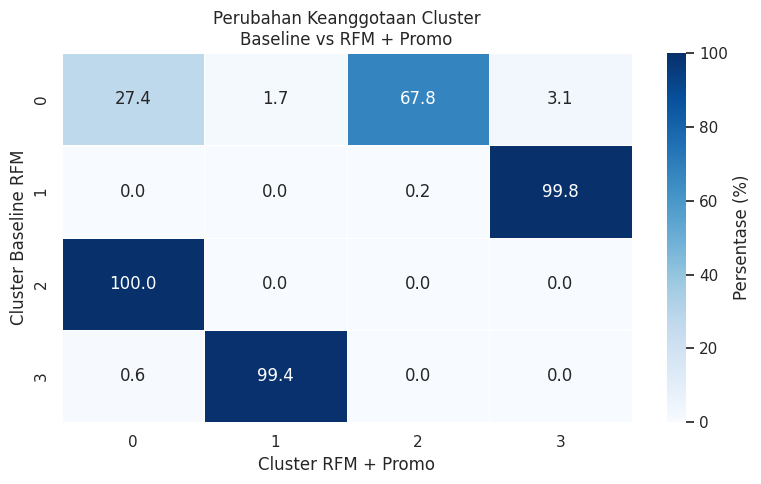

In [36]:

# =====================================================
# 33. PERBANDINGAN KEANGGOTAAN CLUSTER
# =====================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prediksi kedua model pada validation yang sama
labels_baseline = model_baseline[4].predict(
    X_val_rfm
)

labels_promo = model_promo[4].predict(
    X_val_promo
)

# Tabel silang
perbandingan_cluster = pd.crosstab(
    pd.Series(labels_baseline, name="Baseline RFM"),
    pd.Series(labels_promo, name="RFM + Promo")
)

print("=== JUMLAH PELANGGAN LINTAS CLUSTER ===")
display(perbandingan_cluster)

# Persentase per cluster baseline
perbandingan_pct = (
    perbandingan_cluster.div(
        perbandingan_cluster.sum(axis=1),
        axis=0
    ) * 100
)

print("\n=== PERSENTASE PER CLUSTER BASELINE ===")
display(perbandingan_pct.round(2))

# Heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    perbandingan_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Persentase (%)"}
)

plt.title(
    "Perubahan Keanggotaan Cluster\nBaseline vs RFM + Promo"
)

plt.xlabel("Cluster RFM + Promo")
plt.ylabel("Cluster Baseline RFM")

plt.tight_layout()
plt.show()



### 8.9 Evaluasi Perubahan Keanggotaan Cluster

Perbandingan baseline RFM k=4 dan RFM + Promo k=4 pada validation set menghasilkan Adjusted Rand Index (ARI) sebesar 0,7592.

Hasil analisis keanggotaan menunjukkan bahwa 99,77% pelanggan kurang aktif, 100% pelanggan pembeli produk acara, dan 99,42% pelanggan rutin bernilai tinggi dari baseline tetap berada dalam kelompok masing-masing pada model RFM + Promo, meskipun nomor clusternya berbeda.

Perubahan terbesar terjadi pada Cluster 0 baseline. Sebanyak 67,84% anggotanya masuk ke Cluster 2 RFM + Promo dan 27,36% masuk ke Cluster 0 RFM + Promo.

Penambahan fitur promo menghasilkan kelompok dengan penggunaan promo lebih tinggi, tetapi konsentrasi kategori acara pada segmen terkait menurun dari 83,33% menjadi 66,98% pada validation set. Nominal transaksi agregatnya juga lebih rendah.

Dengan demikian, eksperimen menunjukkan adanya trade-off antara pemisahan perilaku penggunaan promo dan kekhususan segmen pembelian produk acara.

Baseline RFM k=4 dipertahankan sebagai kandidat utama karena kesederhanaan dan interpretabilitasnya. Keputusan final menunggu evaluasi stabilitas terhadap perubahan sampel training.


In [37]:

# =====================================================
# 34. STABILITAS TERHADAP PERUBAHAN SAMPEL TRAINING
# =====================================================

from sklearn.base import clone
from sklearn.metrics import adjusted_rand_score
import pandas as pd

kandidat_resampling = {
    "Baseline RFM k=4": {
        "model": model_baseline[4],
        "features": FEATURES_RFM
    },
    "RFM + Promo k=4": {
        "model": model_promo[4],
        "features": FEATURES_PROMO
    }
}

SEEDS_RESAMPLING = [
    11, 29, 47, 83, 101,
    131, 167, 199, 223, 251
]

hasil_resampling = []

for nama, config in kandidat_resampling.items():

    model_referensi = config["model"]
    features = config["features"]

    X_train_model = df_train[features].copy()
    X_val_model = df_val[features].copy()

    # Referensi dari model full training
    label_referensi = model_referensi.predict(
        X_val_model
    )

    for seed in SEEDS_RESAMPLING:

        # Ambil 80% training tanpa pengembalian
        X_subset = X_train_model.sample(
            frac=0.80,
            replace=False,
            random_state=seed
        )

        # Fit ulang pipeline yang sama
        model_subset = clone(model_referensi)
        model_subset.fit(X_subset)

        # Prediksi pada validation yang sama
        label_subset = model_subset.predict(
            X_val_model
        )

        # Bandingkan dengan hasil full training
        ari = adjusted_rand_score(
            label_referensi,
            label_subset
        )

        ukuran = pd.Series(
            label_subset
        ).value_counts()

        hasil_resampling.append({
            "model": nama,
            "seed": seed,
            "n_training": len(X_subset),
            "ARI": ari,
            "cluster_terkecil_pct": (
                ukuran.min() / len(X_val_model) * 100
            )
        })

        print(f"{nama} | seed={seed} selesai")

df_resampling = pd.DataFrame(hasil_resampling)

print("\n=== DETAIL RESAMPLING ===")
display(df_resampling.round(4))

ringkasan_resampling = (
    df_resampling.groupby("model")
    .agg(
        ARI_mean=("ARI", "mean"),
        ARI_std=("ARI", "std"),
        ARI_min=("ARI", "min"),
        ARI_max=("ARI", "max"),
        cluster_terkecil_min_pct=(
            "cluster_terkecil_pct", "min"
        )
    )
)

print("\n=== RINGKASAN STABILITAS RESAMPLING ===")
display(ringkasan_resampling.round(4))

assert len(df_resampling) == 20
assert (df_resampling["n_training"] == 5600).all()

print("\nUji resampling berhasil!")


Baseline RFM k=4 | seed=11 selesai
Baseline RFM k=4 | seed=29 selesai
Baseline RFM k=4 | seed=47 selesai
Baseline RFM k=4 | seed=83 selesai
Baseline RFM k=4 | seed=101 selesai
Baseline RFM k=4 | seed=131 selesai
Baseline RFM k=4 | seed=167 selesai
Baseline RFM k=4 | seed=199 selesai
Baseline RFM k=4 | seed=223 selesai
Baseline RFM k=4 | seed=251 selesai
RFM + Promo k=4 | seed=11 selesai
RFM + Promo k=4 | seed=29 selesai
RFM + Promo k=4 | seed=47 selesai
RFM + Promo k=4 | seed=83 selesai
RFM + Promo k=4 | seed=101 selesai
RFM + Promo k=4 | seed=131 selesai
RFM + Promo k=4 | seed=167 selesai
RFM + Promo k=4 | seed=199 selesai
RFM + Promo k=4 | seed=223 selesai
RFM + Promo k=4 | seed=251 selesai

=== DETAIL RESAMPLING ===


,model,seed,n_training,ARI,cluster_terkecil_pct
0,Baseline RFM k=4,11,5600,0.9934,11.8000
1,Baseline RFM k=4,29,5600,0.9945,11.6667
2,Baseline RFM k=4,47,5600,0.9946,11.5333
3,Baseline RFM k=4,83,5600,0.9961,11.6000
4,Baseline RFM k=4,101,5600,0.9891,11.8000
5,Baseline RFM k=4,131,5600,0.9953,11.8000
6,Baseline RFM k=4,167,5600,0.9978,11.6000
7,Baseline RFM k=4,199,5600,0.9981,11.6000
8,Baseline RFM k=4,223,5600,0.9961,11.6000
9,Baseline RFM k=4,251,5600,0.9959,11.6000



=== RINGKASAN STABILITAS RESAMPLING ===


,ARI_mean,ARI_std,ARI_min,ARI_max,cluster_terkecil_min_pct
model,,,,,
Baseline RFM k=4,0.9951,0.0026,0.9891,0.9981,11.5333
RFM + Promo k=4,0.9958,0.0037,0.9918,1.0000,21.2667



Uji resampling berhasil!



### 8.10 Evaluasi Stabilitas Resampling dan Pemilihan Model

Pengujian resampling dilakukan melalui 10 percobaan menggunakan 80% data training (5.600 pelanggan) pada setiap percobaan.

Baseline RFM k=4 memperoleh rata-rata ARI sebesar 0,9951, dengan ARI minimum 0,9891. Model RFM + Promo k=4 memperoleh rata-rata ARI sebesar 0,9958, dengan ARI minimum 0,9918.

Kedua model menunjukkan stabilitas yang tinggi terhadap variasi sampel training yang diuji. Perbedaannya tidak cukup besar untuk menjadi satu-satunya dasar pemilihan model.

Berdasarkan keseluruhan evaluasi, dipilih **baseline K-Means k=4 menggunakan fitur Recency, Frequency, dan Monetary dengan StandardScaler**.

Pemilihan didasarkan pada kualitas clustering yang baik, stabilitas, kesederhanaan implementasi, serta kemampuan membentuk empat segmen bisnis yang dapat diinterpretasikan.

Informasi penggunaan promo dan kategori favorit tetap dimanfaatkan untuk profiling dan perancangan strategi pemasaran, tetapi tidak digunakan sebagai fitur pembentuk cluster.

Konfigurasi model dibekukan sebelum evaluasi akhir pada holdout test set. Test set tidak digunakan untuk pemilihan algoritma, fitur, jumlah cluster, maupun hyperparameter.


In [38]:

# =====================================================
# 35. FINAL EVALUATION - HOLDOUT TEST SET
# =====================================================

from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

# Model final yang sudah dipilih.
# Tidak melakukan fit ulang.
model_final = model_baseline[4]

FEATURES_FINAL = FEATURES_RFM.copy()

# A. Menyiapkan holdout test
X_test_final = (
    df_test[FEATURES_FINAL]
    .astype("float64")
    .copy()
)

# B. Pemeriksaan data sebelum inferensi
assert len(X_test_final) == 1500
assert X_test_final.notna().all().all()
assert np.isfinite(X_test_final.to_numpy()).all()
assert (X_test_final >= 0).all().all()

# C. Prediksi dengan model training yang sudah ada
label_test = model_final.predict(X_test_final)

# D. Gunakan scaler yang sudah dipelajari dari training
X_test_scaled = model_final[:-1].transform(
    X_test_final
)

# E. Silhouette test
silhouette_test = silhouette_score(
    X_test_scaled,
    label_test
)

# F. Ringkasan evaluasi final
evaluasi_final = pd.DataFrame({
    "dataset": ["Training", "Validation", "Test"],
    "jumlah_pelanggan": [7000, 1500, 1500],
    "silhouette": [
        df_baseline.loc[
            df_baseline["k"] == 4,
            "silhouette_train"
        ].iloc[0],
        df_baseline.loc[
            df_baseline["k"] == 4,
            "silhouette_val"
        ].iloc[0],
        silhouette_test
    ]
})

print("=== EVALUASI FINAL MODEL RFM K=4 ===")
display(evaluasi_final.round(4))

# G. Profil cluster test untuk pelaporan
df_test_profile = df_test.copy()
df_test_profile["cluster"] = label_test

df_test_profile["kategori_acara"] = (
    df_test_profile["kategori_favorit"]
    .isin(["kue_ulang_tahun", "paket_snack"])
)

profil_test_final = (
    df_test_profile
    .groupby("cluster")
    .agg(
        jumlah_pelanggan=("id_pelanggan", "size"),
        recency_mean=(
            "hari_sejak_transaksi_terakhir", "mean"
        ),
        frequency_mean=(
            "jumlah_transaksi_6bln", "mean"
        ),
        monetary_mean=("total_belanja_rp", "mean"),
        promo_mean=("persen_pakai_promo", "mean"),
        kategori_acara_pct=("kategori_acara", "mean")
    )
)

profil_test_final["persen_pelanggan"] = (
    profil_test_final["jumlah_pelanggan"]
    / len(df_test_profile) * 100
)

profil_test_final["kategori_acara_pct"] *= 100

print("\n=== PROFIL CLUSTER HOLDOUT TEST ===")
display(profil_test_final.round(2))

# H. Validasi akhir
assert len(label_test) == 1500
assert len(np.unique(label_test)) == 4
assert (
    profil_test_final["jumlah_pelanggan"].sum()
    == 1500
)

print("\nEvaluasi holdout test berhasil!")


=== EVALUASI FINAL MODEL RFM K=4 ===


,dataset,jumlah_pelanggan,silhouette
0,Training,7000,0.5525
1,Validation,1500,0.5619
2,Test,1500,0.5497



=== PROFIL CLUSTER HOLDOUT TEST ===


,jumlah_pelanggan,recency_mean,frequency_mean,monetary_mean,promo_mean,kategori_acara_pct,persen_pelanggan
cluster,,,,,,,
0,536,14.61,10.25,413978.17,59.08,25.56,35.73
1,428,117.21,2.56,107300.47,33.99,15.65,28.53
2,165,29.95,4.70,1385447.27,13.26,86.06,11.00
3,371,5.11,30.67,1497275.47,19.04,9.16,24.73



Evaluasi holdout test berhasil!



## 9. Evaluasi Akhir Model Terpilih

Model terpilih adalah K-Means dengan k=4 menggunakan fitur Recency, Frequency, dan Monetary yang distandardisasi menggunakan StandardScaler.

Evaluasi akhir dilakukan satu kali pada holdout test set yang berisi 1.500 pelanggan dan tidak digunakan selama proses pemilihan model.

Hasil silhouette:
- Training: 0,5525 (sampel 1.500 pelanggan)
- Validation: 0,5619
- Test: 0,5497

Silhouette test yang relatif dekat dengan training dan validation menunjukkan bahwa kualitas pemisahan cluster tidak mengalami penurunan besar pada holdout acak.

Profil pelanggan pada test set tetap memperlihatkan empat karakteristik utama: pelanggan aktif berorientasi promo, pelanggan kurang aktif, pembeli produk acara bernilai tinggi, serta pelanggan rutin bernilai tinggi.

Hasil ini mendukung penggunaan model untuk prototipe segmentasi dan penyusunan rekomendasi promosi berbasis profil pelanggan.

Keterbatasan penelitian meliputi penggunaan dataset sintetis, evaluasi menggunakan pembagian data acak, serta belum tersedianya pengukuran dampak promosi secara langsung.

Konfigurasi model tidak diubah setelah evaluasi test. Tahap berikutnya adalah menyimpan pipeline dan metadata agar dapat digunakan secara konsisten dalam aplikasi.


In [39]:

# =====================================================
# 36. SIMPAN MODEL FINAL DAN METADATA
# =====================================================

import joblib
import json
import sklearn

from pathlib import Path

# Lokasi folder proyek di Google Drive
PROJECT_DIR = Path(
    "/content/drive/MyDrive/ML_P4P5_Segmentasi_UMKM"
)

assert Path("/content/drive/MyDrive").exists(), (
    "Google Drive belum ter-mount."
)

ARTIFACT_DIR = PROJECT_DIR / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ARTIFACT_DIR / "kmeans_rfm_v1.joblib"
METADATA_PATH = ARTIFACT_DIR / "cluster_metadata.json"

# Gunakan model yang sudah diuji, tanpa refit
model_final = model_baseline[4]

# Nama segmen berdasarkan profiling TRAINING
CLUSTER_NAMES = {
    "0": "Aktif Berorientasi Promo",
    "1": "Pelanggan Kurang Aktif",
    "2": "Pembeli Produk Acara Bernilai Tinggi",
    "3": "Pelanggan Rutin Bernilai Tinggi"
}

# Metadata untuk inferensi dan dokumentasi
metadata = {
    "model_name": "K-Means RFM UMKM",
    "model_version": "1.0",
    "algorithm": "KMeans",
    "preprocessing": "StandardScaler",
    "n_clusters": 4,
    "random_state": 42,
    "n_init": 10,
    "sklearn_version": sklearn.__version__,
    "feature_order": list(FEATURES_RFM),
    "feature_descriptions": {
        "hari_sejak_transaksi_terakhir":
            "Jumlah hari sejak transaksi terakhir",
        "jumlah_transaksi_6bln":
            "Jumlah transaksi selama enam bulan",
        "total_belanja_rp":
            "Total belanja enam bulan dalam rupiah"
    },
    "cluster_names": CLUSTER_NAMES,
    "training_rows": 7000,
    "validation_rows": 1500,
    "test_rows": 1500,
    "evaluation": {
        "silhouette_train_sample": 0.5525,
        "silhouette_validation": 0.5619,
        "silhouette_test": 0.5497
    },
    "notes": (
        "Nama cluster berasal dari profiling training. "
        "Penggunaan promo dan kategori favorit bukan "
        "fitur input K-Means. Dataset bersifat sintetis."
    )
}

# Simpan pipeline
joblib.dump(model_final, MODEL_PATH)

# Simpan metadata JSON
with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(
        metadata,
        f,
        ensure_ascii=False,
        indent=2
    )

print("=== MODEL FINAL TERSIMPAN ===")
print("Model    :", MODEL_PATH)
print("Metadata :", METADATA_PATH)

assert MODEL_PATH.exists()
assert METADATA_PATH.exists()

print("\nPenyimpanan berhasil!")


=== MODEL FINAL TERSIMPAN ===
Model    : /content/drive/MyDrive/ML_P4P5_Segmentasi_UMKM/artifacts/kmeans_rfm_v1.joblib
Metadata : /content/drive/MyDrive/ML_P4P5_Segmentasi_UMKM/artifacts/cluster_metadata.json

Penyimpanan berhasil!


In [40]:

# =====================================================
# 37. SMOKE TEST - PREDIKSI PELANGGAN BARU
# =====================================================

import pandas as pd
import joblib
import json

# Muat kembali model dan metadata
loaded_model = joblib.load(MODEL_PATH)

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    loaded_metadata = json.load(f)

# Contoh pelanggan fiktif, bukan data test
pelanggan_baru = pd.DataFrame([{
    "hari_sejak_transaksi_terakhir": 12,
    "jumlah_transaksi_6bln": 8,
    "total_belanja_rp": 400000
}])

# Pastikan urutan fitur sesuai metadata
pelanggan_baru = pelanggan_baru[
    loaded_metadata["feature_order"]
]

# Prediksi menggunakan model yang di-load
cluster_prediksi = int(
    loaded_model.predict(pelanggan_baru)[0]
)

nama_segmen = loaded_metadata[
    "cluster_names"
][str(cluster_prediksi)]

print("=== SIMULASI PELANGGAN BARU ===")
display(pelanggan_baru)

print("\nCluster hasil prediksi:", cluster_prediksi)
print("Nama segmen:", nama_segmen)

# Pastikan model tersimpan konsisten
prediksi_sebelum = int(
    model_final.predict(pelanggan_baru)[0]
)

assert cluster_prediksi == prediksi_sebelum
assert len(loaded_metadata["feature_order"]) == 3

print("\nSmoke test berhasil!")


=== SIMULASI PELANGGAN BARU ===


,hari_sejak_transaksi_terakhir,jumlah_transaksi_6bln,total_belanja_rp
0,12,8,400000



Cluster hasil prediksi: 0
Nama segmen: Aktif Berorientasi Promo

Smoke test berhasil!
